# Notebook 06 — Predecir si una síntesis cristaliza: un caso completo de ciencia de datos

**Proyecto:** ALCheMy · **Autor:** Rubén Serrano Nieto & AI Agent Pair · **Fecha:** 2026-08-29 (v3)

---

### Cómo leer este cuaderno

Este cuaderno recorre **un problema de ciencia de datos de principio a fin**: desde
"¿qué pregunta de laboratorio quiero contestar?" hasta un modelo evaluado y un análisis
de qué variables químicas mandan. No es un script que entrena un modelo: es el registro
de por qué cada decisión se tomó como se tomó, **incluidas las que salieron mal**.

Está estructurado según el **marco metodológico de 10 etapas**, que es el refinamiento
más usado de **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*, 1999 — el
estándar de facto de la industria, todavía hoy). Las dos dicen lo mismo con distinto
grano; la de 10 etapas separa mejor las primeras fases, que es justo donde se juega un
proyecto de investigación como este.

| Etapa (10 etapas) | Fase CRISP-DM | ¿Dónde está aquí? |
|---|---|---|
| 1. Comprensión del problema | Business Understanding | §1 |
| 2. Enfoque analítico | Business Understanding | §2 |
| 3. Requisitos de datos | Data Understanding | §3 |
| 4. Recolección de datos | Data Understanding | §4 |
| 5. Comprensión de los datos | Data Understanding | §5 (EDA) |
| 6. Preparación de los datos | Data Preparation | §6 (ETL) |
| 7. Modelado | Modeling | §7 |
| 8. Evaluación | Evaluation | §8 |
| 9. Despliegue | Deployment | §9 |
| 10. Retroalimentación | Deployment | §10 |

**El ciclo no es una lista, es un bucle.** Este cuaderno es la prueba: la versión
anterior llegó hasta la etapa 8 con un resultado aparentemente bueno, y una revisión
química lo devolvió a las etapas 3 y 6. Lo que sigue es la segunda vuelta.

> **Nota sobre las figuras.** Los rótulos, ejes y títulos de las figuras están en inglés
> (convención de publicación científica); el razonamiento va en castellano.

### Índice

- **§1** El problema · **§2** Clasificación o regresión · **§3** Qué datos hacen falta
- **§4** De dónde sale cada número · **§5** EDA · **§6** Preparación y ETL
- **§7** Modelado · **§8** Evaluación · **§9** Despliegue · **§10** Retroalimentación

---

> ### 📌 Qué cambió en esta versión, y por qué importa
>
> La v2 de este cuaderno reportaba **F1 macro 0,62**. Esta reporta **0,52**. El número
> ha bajado, y esa bajada es el resultado más importante del cuaderno.
>
> Una revisión experta encontró **siete defectos** en la preparación de los datos.
> Ninguno lo había detectado ninguna métrica: la validación cruzada no se quejó nunca.
> Los tres que más pesaban:
>
> | | Defecto | Efecto |
> |---|---|---|
> | 1 | Los moduladores líquidos puros estaban en **µmol etiquetados como mmol** (factor 1.000), y se sumaban con HCl y HF que sí estaban en mmol | El HCl —el modulador más usado— quedaba **numéricamente borrado** del modelo |
> | 2 | **El tipo de síntesis no era una variable**, y era el mayor factor de confusión: microondas 95,7 % cristalino frente a combinatoria 11,0 % | Parte del rendimiento venía de detectar el **método**, no la química |
> | 3 | Dos disolventes fuera de la tabla, y el modulador líquido —que a veces **es** el disolvente— sin contar como medio | La composición del medio estaba mal |
>
> Corregido todo, el modelo baja de 0,62 a 0,52. **No es un retroceso: es que 0,62 no
> era verdad.** Los seis defectos salieron de leer los números con criterio químico, no
> de ninguna métrica — y eso es un resultado sobre el método tan valioso como el modelo.

---

# §1. Comprensión del problema

> *Etapa 1 — Business Understanding. Qué se quiere conseguir, en el lenguaje de quien
> tiene el problema. Si esta etapa se hace mal, todo lo demás está bien hecho pero
> resuelve otra cosa.*

### La pregunta del laboratorio

Sintetizar un MOF de fosfonato lleva **entre 24 y 96 horas de estufa**, más el tiempo de
pesar, montar y caracterizar. De cada 24 pocillos de una placa de síntesis en
combinatoria, la mayoría no cristalizan. La pregunta es directa:

> **¿Se puede predecir, *antes* de meter nada en la estufa, si una combinación de
> condiciones va a producir material cristalino?**

### Para qué serviría exactamente

1. **Descartar** combinaciones condenadas al fracaso antes de gastar 48 h de estufa.
2. **Priorizar** el siguiente lote: si caben 24 pocillos, llenarlos con los 24
   candidatos más prometedores en vez de con una rejilla ciega.
3. **Entender** qué gobierna la cristalización en esta familia química — que es, a la
   larga, lo más valioso: un modelo que acierta sin explicar no enseña nada.

### El criterio de éxito, fijado ANTES de ver resultados

Esto no es formalismo: es la única defensa contra elegir la métrica que mejor queda
después. Se fija ahora:

- **Mínimo aceptable:** batir de forma clara a la clase mayoritaria en **F1 macro**.
- **Útil de verdad:** que el orden de candidatos sirva para llenar una placa mejor que
  el azar.
- **Irrenunciable:** que el modelo sea **interpretable en términos químicos**. Un
  acierto sin explicación no cambia cómo se trabaja en el laboratorio.

---

# §2. Enfoque analítico

> *Etapa 2 — Analytic Approach. Traducir la pregunta del laboratorio a un tipo de
> problema estadístico. Elegir mal aquí no se arregla luego con más modelos.*

### El árbol de decisión

| Si la pregunta es… | Entonces… |
|---|---|
| ¿A qué **categoría** pertenece? | **Clasificación supervisada** |
| ¿Qué **valor numérico** tomará? | Regresión supervisada |
| ¿Hay **grupos naturales** sin etiquetas? | Clustering (no supervisado) |
| ¿Puedo **resumir** muchas columnas? | Reducción de dimensionalidad (PCA…) |

### Por qué clasificación y no regresión

Es la decisión de diseño más importante del cuaderno, y podría haber ido al revés.
Existe un candidato razonable a variable continua: `amorphous_fraction_blank`, la
fracción de lo que dispersó la muestra que fue difusa en vez de picos de Bragg — un
número entre 0 y 1 que *parece* medir "cuán cristalino" es el material. Predecir ese
número sería una regresión.

**Se descartó por tres razones, en orden de peso:**

1. **La variable continua no es fiable en sus extremos.** Tiene un suelo de detección de
   ~0,02 (notebook 05 §7.5): por debajo, el número es ruido residual de la línea base,
   no señal. Una regresión trataría la diferencia entre 0,005 y 0,015 como información
   real cuando ambos significan lo mismo — "nada medible". Y la clase CRISTALINO vive
   entera en esa zona ciega.
2. **La decisión del laboratorio es categórica.** El laboratorio no decide "repetir esta
   síntesis" en función de si la fracción amorfa es 0,42 o 0,48; decide en función de si
   aquello cristalizó, cristalizó a medias, o no cristalizó. **El modelo debe predecir la
   decisión que se va a tomar**, no un número del que luego habría que decidir.
3. **La etiqueta de verdad es un juicio humano categórico.** Lo que hay etiquetado a mano
   —y es lo que da la verdad de referencia— son tres clases, no un número.

> **Nota sobre las métricas, que responde a una duda frecuente.** Indicadores como el
> **MRE** (error relativo medio), el RMSE o el R² son de **regresión**: miden *cuánto* te
> alejas de un número. En clasificación no hay distancia: o aciertas la clase o no. Los
> equivalentes correctos son **F1 macro, MCC y exactitud equilibrada**, y se explican
> uno a uno en §8.1.

### Las tres clases

| Clase | Qué significa físicamente |
|---|---|
| **AMORFO** | Sólo halo difuso: no hay orden de largo alcance |
| **INCIPIENTE** | Picos débiles sobre un halo dominante: empezó a ordenarse |
| **CRISTALINO** | Picos de Bragg definidos |

Son **ordinales** (amorfo < incipiente < cristalino), y eso importará al leer los
errores en §8.3: confundir clases vecinas no es lo mismo que confundir los extremos.

---

# §3. Requisitos de datos

> *Etapa 3 — Data Requirements. Qué haría falta idealmente, declarado ANTES de mirar qué
> hay. Al revés, uno acaba justificando los datos que tiene.*

### Lo que un químico pediría para responder a §1

| Bloque | Variables ideales | ¿Disponible? |
|---|---|---|
| **Metal** | Identidad, estado de oxidación, radio iónico, dureza, oxofilicidad | ✅ Construido (§4.2) |
| **Linker** | Esqueleto, denticidad, longitud, estado de protección | ✅ Construido (§4.2) |
| **Estequiometría** | [M], relación L/M | ✅ En el Excel maestro |
| **Medio** | Composición del disolvente, **pH** | ⚠️ Composición sí; **pH no se registró nunca** |
| **Modulador** | Cuánto, y de qué tipo (acidez, polaridad) | ✅ Tras la corrección de §6 |
| **Proceso** | Temperatura, tiempo, rampas | ✅ En el Excel maestro |
| | **Presión autógena** | ❌ No medida |
| **Resultado** | Clase de cristalinidad | ✅ Etiquetado a mano |

### Los huecos, declarados por adelantado

- **El pH no está.** En química de fosfonatos es probablemente **la variable ausente más
  importante**: gobierna el grado de desprotonación del linker y por tanto su capacidad
  de coordinar. Todo lo que sigue se hace sabiendo que falta.
- **La presión autógena tampoco**, aunque es en parte función de temperatura, volumen y
  disolvente, que sí están — así que está *parcialmente* representada.

Declararlos ahora tiene una consecuencia concreta: cuando en §8 una variable de proceso
salga poco importante, habrá que distinguir entre *"no importa"* y *"no lo medimos"*.

---

# §4. Recolección de datos

> *Etapa 4 — Data Collection. De dónde sale cada número, y qué hubo que construir porque
> no existía.*

### 4.1 El ciclo del dato en ALCheMy, de la libreta al modelo

Nada de esto empezó siendo una tabla. El recorrido completo:

```mermaid
flowchart TD
    subgraph G1["(1) Fuentes crudas"]
        A1["Excel maestro de síntesis<br/>(5 años de libretas)"]
        A2["~5.700 ficheros de instrumento<br/>(.xrdml .brml .txt .csv .xls .jpg)"]
    end
    subgraph G2["(2) Ingesta"]
        B1["notebook 01: renombrado, ingeniería estequiométrica<br/>(µL → mmol activos), rampas térmicas,<br/>clave natural MD5, UPSERT"]
        B2["parsers deterministas<br/>(contrato común: header_metadata + raw_data)"]
    end
    subgraph G3["(3) Almacén"]
        C1[("synthesis_experiments<br/>1 fila / síntesis")]
        C2[("characterization_measurements<br/>1 fila / medida, JSONB + GIN")]
    end
    D1["(4) notebook 05: arPLS, separación de halo, detección de picos"]
    D2[("pxrd_descriptors")]
    D3["app/pxrd_labeler.py (juicio humano)"]
    D4>"pxrd_labels — LA ETIQUETA (Y)"]
    E1["(5) element_properties + ion_properties + linker_properties"]
    E2[("v_ml_features — LAS CARACTERÍSTICAS (X)")]
    F1["(6) Este cuaderno: §5 EDA → §6 ETL → §7 modelos → §8 evaluación"]
    F2{{"(7) Revisión experta<br/>devuelve el trabajo a §3 y §6"}}

    A1 --> B1 --> C1
    A2 --> B2 --> C2
    C2 -->|FK| C1
    C2 --> D1 --> D2 --> D3 --> D4
    C1 --> E1 --> E2
    C1 --> E2
    D4 --> F1
    E2 --> F1
    F1 --> F2
    F2 -.->|corrige| B1
    F2 -.->|corrige| E2

    classDef raw fill:#ECEFF1,stroke:#78909C,color:#263238
    classDef proc fill:#F1F8E9,stroke:#7CB342,color:#33691E
    classDef store fill:#E3F2FD,stroke:#1E88E5,color:#0D47A1
    classDef target fill:#FFF3E0,stroke:#FB8C00,color:#E65100
    classDef human fill:#FCE4EC,stroke:#D81B60,color:#880E4F
    class A1,A2 raw
    class B1,B2,D1,D3 proc
    class C1,C2,D2,E2 store
    class D4 target
    class F2 human
```

**Las flechas de vuelta no son decorativas.** Son lo que ocurrió de verdad entre la v2 y
la v3 de este cuaderno.

### 4.2 Lo que hubo que construir: la química como número

El Excel maestro guarda el metal como **texto** (`"Zr"`) y el linker como **texto**
(`"H8ptp"`). Un modelo no puede hacer nada con eso salvo memorizar nombres.

La alternativa fácil sería *one-hot*: una columna por metal, 20 columnas de ceros y unos.
Se descartó, y la razón es química: **el one-hot dice que el Zr y el Hf son tan distintos
entre sí como el Zr y el Ca**. Y no lo son — Zr y Hf son casi gemelos por la contracción
lantánida. Un modelo con one-hot no puede transferir nada de lo aprendido con Zr al Hf, y
menos aún a un metal nuevo que no estuviera en el entrenamiento.

Por eso se construyeron cinco tablas de referencia que traducen identidad a propiedades:

| Tabla | Qué aporta |
|---|---|
| `element_properties` | Electronegatividad, dureza, polarizabilidad, oxofilicidad |
| `ion_properties` | Radio iónico y carga/radio **por estado de oxidación** (Shannon, CN=6) |
| `metal_source_oxidation_state` | Qué carga implica cada fórmula de sal precursora |
| `linker_properties` | Esqueleto, protección, denticidad, distancia entre donores |
| `property_sources` | La cita y el DOI de cada propiedad |

**Dos decisiones que merecen argumentarse:**

- **El estado de oxidación sale de la fórmula del precursor, no de "lo típico del
  elemento".** El hierro puede entrar como Fe(II) o Fe(III), el cerio como Ce(III) o
  Ce(IV), y eso cambia por completo el radio y la densidad de carga. Se deduce del
  balance de carga de la sal que de verdad se pesó.
- **Pocos descriptores de linker, elegidos a mano.** RDKit ofrece más de 200. Hay
  **4 linkers**. Más descriptores que moléculas es una trampa de memorización, no señal.

---

# §5. Comprensión de los datos (EDA)

> *Etapa 5 — Data Understanding. Mirar los datos antes de modelar. Es la etapa que más
> devuelve por hora invertida, y la que más se salta.*

Antes de cargar nada, **la decisión que define el conjunto**.

### 5.0 Qué síntesis entran: el factor de confusión que casi arruina el análisis

El histórico tiene tres formas de sintetizar, y la v2 de este cuaderno las mezcló sin
mirarlas. Los números:

| Tipo | AMORFO | CRISTALINO | INCIPIENTE | **% cristalino** |
|---|---:|---:|---:|---:|
| **HTS** — síntesis en combinatoria | 401 | 169 | 971 | **11,0 %** |
| **ST** — solvotermal estándar | 3 | 71 | 15 | **79,8 %** |
| **MW** — microondas | 0 | 90 | 4 | **95,7 %** |

**Cero muestras amorfas en microondas.** Un modelo entrenado sobre los tres mezclados
tiene un atajo enorme disponible: si detecta —aunque sea indirectamente, por el volumen
del reactor o el año— que una síntesis es de microondas, puede cantar CRISTALINO y
acertar el 96 % de las veces. Los 94 casos de microondas eran el 5 % del conjunto pero el
**27 % de toda la clase CRISTALINO**.

**Y no es un efecto del método: es sesgo de selección.** La combinatoria es
*exploratoria* — se barren condiciones sin saber qué va a salir, y por eso está llena de
fracasos. La estándar y el microondas se usan **cuando ya sabes que la receta funciona** y
quieres escalar o acelerar. La variable "tipo de síntesis" codifica, en buena parte,
*"¿sabías ya que esto iba a salir?"*. Predecir eso no es química, es leer el historial.

**Hay además un argumento térmico independiente**, que valdría aunque no hubiera sesgo:
el microondas calienta de forma **localizada y rápida**, lo que favorece las fases
cinéticas frente a las termodinámicas. La relación entre condiciones y producto **no es
la misma función** en microondas que en estufa. Mezclarlos obliga al modelo a aprender
dos físicas distintas como si fueran una.

### La decisión: sólo HTS

> **Se entrena únicamente con síntesis en combinatoria (HTS).**
>
> 1. Es el único subconjunto **sin sesgo de éxito**: se diseñó para explorar, no para
>    confirmar.
> 2. Es aquel sobre el que de verdad se quiere predecir — **la próxima placa es una placa
>    HTS**.
> 3. Es un **único régimen térmico**, así que el modelo aprende una física, no dos.
>
> **El precio es real y se dice:** se pierden 90 de los 330 casos cristalinos (27 %), y
> la clase minoritaria queda aún más escasa. Se paga a conciencia: **un F1 más bajo y
> honesto vale más que uno alto que en realidad detecta el método de síntesis.**

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psycopg2
from dotenv import load_dotenv

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)

# Estilo de figura unico para todo el cuaderno: sobrio, tipo publicacion.
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 110,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 9.5, 'axes.titleweight': 'normal', 'axes.labelsize': 8.5,
    'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5, 'legend.fontsize': 8,
    'font.family': 'DejaVu Sans',
})

# Paleta por clase, con el orden ORDINAL amorfo -> incipiente -> cristalino
C_AMOR, C_INCI, C_CRYS = '#d9a441', '#7e57c2', '#1f7a8c'
CLASS_ORDER  = ['AMORFO', 'INCIPIENTE', 'CRISTALINO']
CLASS_COLORS = {'AMORFO': C_AMOR, 'INCIPIENTE': C_INCI, 'CRISTALINO': C_CRYS}

for p in (r'C:\Users\rubbe\Documents\ALCheMy\.env', '.env', '../.env'):
    if os.path.exists(p):
        load_dotenv(p); break

conn = psycopg2.connect(host='localhost', port=5432, dbname='alchemy_db',
                        user=os.getenv('POSTGRES_USER'),
                        password=os.getenv('POSTGRES_PASSWORD'))
print('Conectado a alchemy_db')

Conectado a alchemy_db


### 5.1 La consulta: qué se pide y qué se excluye, con su porqué

La consulta que define el conjunto es donde viven las decisiones. Cada filtro tiene un
motivo, y ninguno es "para que salga mejor":

| Filtro | Por qué |
|---|---|
| `synthesis_type = 'HTS'` | §5.0: el resto arrastra sesgo de selección y otra física térmica |
| `label_value <> 'SIN_MUESTRA'` | No hay material que clasificar: no es una clase, es un no-dato |
| `ml_include = 'NO'` ausente | Excluye lo que la revisión experta marcó (duplicados, óxidos) — §6.2 |
| `MEZCLA → CRISTALINO` | Una mezcla contiene fase cristalina; para la pregunta de §1, cristalizó |
| `linker <> 'Tannic acid'` | §6.3 — se argumenta allí, con su medida |

In [2]:
CONSULTA = '''
SELECT v.*,
       CASE WHEN lc.label_value = 'MEZCLA' THEN 'CRISTALINO'
            ELSE lc.label_value END AS ml_class
  FROM v_ml_features v
  JOIN characterization_measurements cm ON cm.sample_code = v.sample_code
  JOIN pxrd_labels lc ON lc.measurement_id = cm.measurement_id
                     AND lc.label_type = 'crystallinity_class'
  LEFT JOIN pxrd_labels ex ON ex.measurement_id = cm.measurement_id
                          AND ex.label_type = 'ml_include'
                          AND ex.label_value = 'NO'
 WHERE lc.label_value <> 'SIN_MUESTRA'
   AND ex.measurement_id IS NULL
   AND v.synthesis_type = 'HTS'
   AND v.linker <> 'Tannic acid'
'''
df = pd.read_sql(CONSULTA, conn)

print('filas: %d   |   muestras distintas: %d   |   placas HTS: %d'
      % (len(df), df['sample_code'].nunique(), df['hts_number'].nunique()))
assert len(df) == df['sample_code'].nunique(), 'una muestra aparece mas de una vez'
print('\ncolumnas: %d' % df.shape[1])
df.head(3)

filas: 1516   |   muestras distintas: 1516   |   placas HTS: 68

columnas: 47


,sample_code,hts_number,synthesis_date,metal_center,linker,metal_source,synthesis_type,electronegativity_pauling,electronegativity_allen,absolute_hardness_ev,oxophilicity_kepp,polarizability_a3,oxidation_state,shannon_radius_pm,charge_over_radius,scaffold,protection_state,denticity,n_acidic_protons,max_donor_distance_a,n_rotatable_bonds,metal_conc_m,lm_ratio,temp_target_c,time_hours,heating_rate_c_min,cooling_rate_c_min,total_volume_ml,reactor_volume_ml,fill_fraction,frac_h2o,frac_meoh,frac_etoh,frac_proh,frac_dmf,frac_def,frac_modulator,solvent_breakdown_complete,mod_carboxylic_mmol,mod_strong_acid_mmol,mod_hf_mmol,mod_base_mmol,mod_fluorinated_mmol,mod_total_mmol,mod_carbox_mean_pka,mod_carbox_mean_logp,ml_class
0,LP129,C#72,2024-09-30,Ca,Et8ptp,Ca(NO3)2·4H2O,HTS,1.00,6.113,3.044303,0.3,0.1608,2,114.0,0.017544,pyrene_phosphonate,ethyl_ester,0,0,9.41,20.0,0.03,0.5,130.0,48.0,0.2917,0.1944,1.54,2.5,0.616,0.220779,0.779221,0.0,0.0,0.0,0.0,0.0,True,0.0,0.2000,0.0,0.0,0.0,0.2000,NaN,NaN,CRISTALINO
1,LP40,C#69,2024-08-13,Ca,Et8ptp,Ca(NO3)2·4H2O,HTS,1.00,6.113,3.044303,0.3,0.1608,2,114.0,0.017544,pyrene_phosphonate,ethyl_ester,0,0,9.41,20.0,0.03,0.5,130.0,48.0,0.2917,0.1944,1.51,2.5,0.604,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,0.0,0.0503,0.0,0.0,0.0,0.0503,NaN,NaN,INCIPIENTE
2,RS171,C#5,2021-08-27,Ti,H6ttbmp,Ti-isopropoxide,HTS,1.54,8.170,3.374560,1.0,0.0870,4,74.5,0.053691,triazine_phosphonate,free_acid,3,6,14.17,9.0,0.03,0.5,150.0,48.0,0.2604,0.2500,1.50,2.5,0.600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,0.0,0.0006,0.0,0.0,0.0,0.0006,NaN,NaN,CRISTALINO


**1 fila = 1 muestra física.** La comprobación `assert` no es decorativa: en la v2 del
cuaderno esta igualdad **fallaba** (43 muestras tenían dos medidas etiquetadas), y ese
fallo se convirtió en el trabajo de §6.2.

### 5.2 Perfilado: qué tipo de cosa es cada columna

El primer paso de todo EDA es aburrido y no se puede saltar: para cada columna, qué tipo
tiene, cuántos ausentes, cuántos valores distintos. Es donde aparecen los problemas que
luego cuestan horas.

In [3]:
def perfilar(frame):
    '''Perfil columna a columna: tipo, ausentes, cardinalidad y muestra de valores.'''
    filas = []
    for col in frame.columns:
        s = frame[col]
        filas.append({
            'columna': col,
            'tipo': str(s.dtype),
            'no nulos': s.notna().sum(),
            'nulos': s.isna().sum(),
            'nulos %': round(s.isna().mean() * 100, 2),
            'distintos': s.nunique(),
            'ejemplo': ', '.join(map(str, s.dropna().unique()[:3]))[:44],
        })
    return pd.DataFrame(filas)

perfil = perfilar(df)
perfil

,columna,tipo,no nulos,nulos,nulos %,distintos,ejemplo
0,sample_code,object,1516,0,0.00,1516,"LP129, LP40, RS171"
1,hts_number,object,1516,0,0.00,68,"C#72, C#69, C#5"
2,synthesis_date,object,1516,0,0.00,88,"2024-09-30, 2024-08-13, 2021-08-27"
3,metal_center,object,1516,0,0.00,18,"Ca, Ti, Fe"
4,linker,object,1516,0,0.00,4,"Et8ptp, H6ttbmp, H8ptp"
5,metal_source,object,1516,0,0.00,40,"Ca(NO3)2·4H2O, Ti-isopropoxide, FeCl3.6H2O"
6,synthesis_type,object,1516,0,0.00,1,HTS
7,electronegativity_pauling,float64,1516,0,0.00,17,"1.0, 1.54, 1.83"
8,electronegativity_allen,float64,1474,42,2.77,14,"6.1129999999999995, 8.17, 10.64"
9,absolute_hardness_ev,float64,1378,138,9.10,16,"3.044302735, 3.3745600000000002, 3.87573405"


### 5.3 Los valores ausentes: quién falta, y por qué la mediana no es la respuesta

«Un 9 % de ausentes» es una cifra tranquilizadora que oculta problemas distintos. Un
ausente puede significar *«no se midió»*, *«no existe»* o *«el texto no casó»*, y sólo el
primero se parece a lo que la imputación asume.

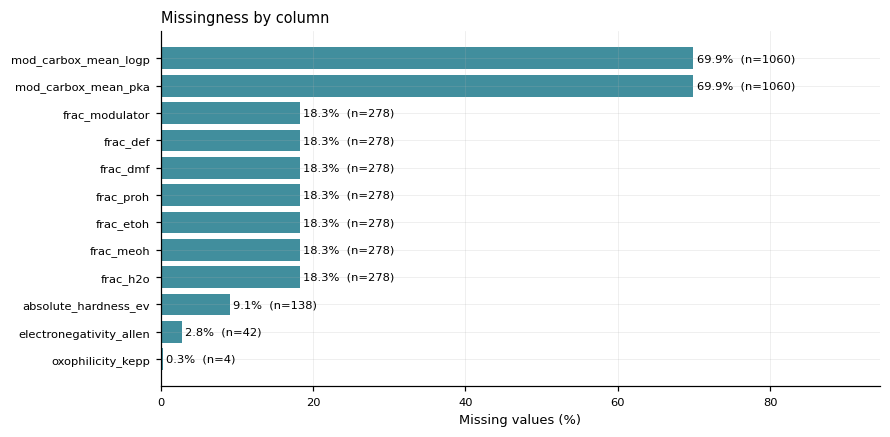

Columns with no missing values: 35 of 47


In [4]:
nulos = (df.isna().mean() * 100)
nulos = nulos[nulos > 0].sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8.2, max(2.4, 0.34 * len(nulos))))
ax.barh(nulos.index, nulos.values, color=C_CRYS, alpha=0.85)
for i, v in enumerate(nulos.values):
    ax.text(v + 0.4, i, '%.1f%%  (n=%d)' % (v, int(round(v / 100 * len(df)))),
            va='center', fontsize=7.5)
ax.set_xlabel('Missing values (%)')
ax.set_xlim(0, max(nulos.values) * 1.35)
ax.set_title('Missingness by column', loc='left')
fig.tight_layout(); plt.show()

print('Columns with no missing values: %d of %d' % ((df.isna().sum() == 0).sum(), df.shape[1]))

In [5]:
# De QUE metal / linker viene cada ausente: la pregunta que la v2 no respondia
def quien_falta(col, clave='metal_center'):
    m = df[col].isna()
    if not m.sum():
        return '-'
    d = df.loc[m].groupby(clave).size().sort_values(ascending=False)
    return ', '.join('%s=%d' % (k, v) for k, v in d.items())

for c in ['electronegativity_allen', 'absolute_hardness_ev', 'oxophilicity_kepp',
          'oxidation_state', 'shannon_radius_pm']:
    if c in df.columns:
        print('%-26s %4d nulos  <-  %s' % (c, df[c].isna().sum(), quien_falta(c)))
for c in ['mod_carbox_mean_pka', 'frac_h2o']:
    print('%-26s %4d nulos' % (c, df[c].isna().sum()))

electronegativity_allen      42 nulos  <-  Ce=30, Dy=4, La=4, Nd=4
absolute_hardness_ev        138 nulos  <-  Mg=117, Zn=21
oxophilicity_kepp             4 nulos  <-  Ga=4
oxidation_state               0 nulos  <-  -
shannon_radius_pm             0 nulos  <-  -
mod_carbox_mean_pka        1060 nulos
frac_h2o                    278 nulos


**Cinco causas distintas, cinco arreglos distintos.** Quién falta exactamente y qué
significa:

| Propiedad | Quién | Por qué falta | Qué se hace |
|---|---|---|---|
| `electronegativity_allen` | **Ce, La, Dy, Nd** | La escala de Allen es espectroscópica y **no está definida para lantánidos** | **Se retira la columna.** No es un hueco: es que no existe. Pauling cubre los 20 metales y se queda |
| `absolute_hardness_ev` | **Mg, Zn** | η = (EI−AE)/2, y no hay afinidad electrónica: sus capas llenas (3s², 3d¹⁰4s²) **no fijan un electrón extra** | Se imputa, sabiendo que es imperfecto: la mediana sitúa al Mg²⁺ entre metales de transición, y el Mg²⁺ es un ion duro |
| `oxophilicity_kepp` | **Ga** | **No aparece** en la tabla del artículo original (del grupo III sólo B, Al, In) | Nulo permanente y documentado |
| `oxidation_state`, radio | *(resuelto)* | El texto del precursor llevaba un **espacio duro** (U+00A0): `MgCl2 · 6H2O` no casaba con la tabla de mapeo | **Arreglado en §6.1** normalizando el emparejamiento, no añadiendo variantes a mano |
| `mod_carbox_mean_pka` | ~70 % de las filas | **No es un fallo:** esas síntesis no llevan modulador carboxílico, y "sin ácido" no tiene pKa | Se imputa; se comprobó (§6.4) que marcar el ausente no aporta |
| `frac_*` (medio) | ~18 % de las filas | El histórico registró el volumen total pero no su reparto | **NULL, no 0** — §6.1: "no se registró" ≠ "no había" |

La última fila es la lección de fondo: **poner un 0 donde el dato es desconocido no es
neutro, es afirmar algo falso.** Decirle al modelo "esta síntesis no llevaba metanol"
cuando la verdad es "no consta cuánto metanol llevaba" es meterle una mentira con
apariencia de dato.

### 5.4 La variable objetivo: cuánto desequilibrio hay

Antes de cualquier otra cosa, mirar la variable que se quiere predecir. El desequilibrio
condiciona la métrica (§8.1), la validación y hasta qué modelos tienen sentido.

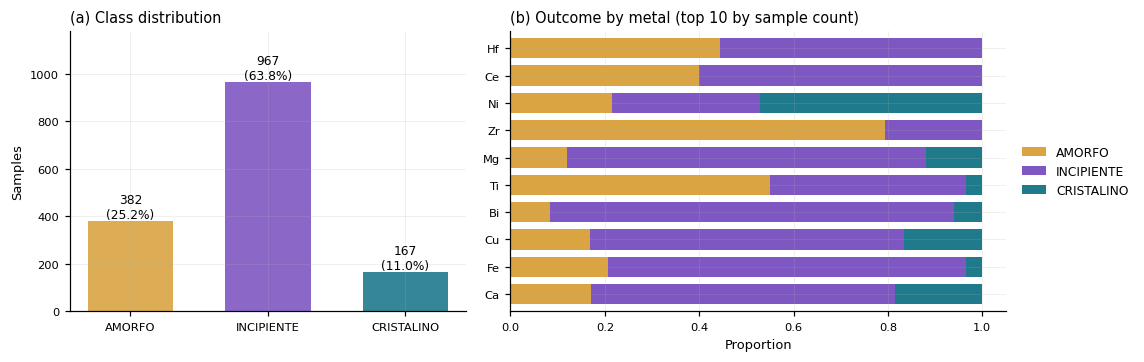

Desequilibrio  mayoritaria/minoritaria = 5.8 : 1
Acierto de un modelo que siempre diga la clase mayoritaria: 63.8 %


In [6]:
cuenta = df['ml_class'].value_counts().reindex(CLASS_ORDER)
prop = 100 * cuenta / cuenta.sum()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4), gridspec_kw={'width_ratios': [1, 1.25]})
axes[0].bar(cuenta.index, cuenta.values, color=[CLASS_COLORS[c] for c in cuenta.index],
            alpha=0.9, width=0.62)
for i, (n, p) in enumerate(zip(cuenta.values, prop.values)):
    axes[0].text(i, n + 12, '%d\n(%.1f%%)' % (n, p), ha='center', fontsize=8)
axes[0].set_ylabel('Samples'); axes[0].set_ylim(0, cuenta.max() * 1.22)
axes[0].set_title('(a) Class distribution', loc='left')

orden_m = df.groupby('metal_center').size().sort_values(ascending=False).head(10).index
ct = pd.crosstab(df.loc[df['metal_center'].isin(orden_m), 'metal_center'], df['ml_class'])
ct = ct.reindex(index=orden_m, columns=CLASS_ORDER).fillna(0)
(ct.div(ct.sum(axis=1), axis=0)).plot(kind='barh', stacked=True, ax=axes[1], width=0.75,
                                      color=[CLASS_COLORS[c] for c in CLASS_ORDER])
axes[1].set_xlabel('Proportion'); axes[1].set_ylabel('')
axes[1].legend(title='', loc='center left', bbox_to_anchor=(1.01, 0.5), frameon=False)
axes[1].set_title('(b) Outcome by metal (top 10 by sample count)', loc='left')
fig.tight_layout(); plt.show()

print('Desequilibrio  mayoritaria/minoritaria = %.1f : 1' % (cuenta.max() / cuenta.min()))
print('Acierto de un modelo que siempre diga la clase mayoritaria: %.1f %%' % prop.max())

**Ese último número es la trampa que hay que tener presente todo el cuaderno.** Un
modelo que no aprende nada —que dice siempre "INCIPIENTE"— acierta ~64 % de las veces. Si
al final reportáramos "64 % de exactitud" sonaría a que el modelo hace algo, y no haría
nada en absoluto. Por eso §8.1 usa métricas que penalizan exactamente ese comportamiento.

El desequilibrio es **5,8:1** entre la mayoritaria y la minoritaria — más acusado que
antes de quedarnos sólo con HTS, porque justamente lo que se retiró era casi todo
cristalino. Se compensa **ponderando las clases** dentro de cada modelo
(`class_weight='balanced'`), que es más simple que remuestrear y no inventa muestras.

**(b)** ya adelanta algo importante: la fracción de cristalino **cambia mucho entre
metales**. Hay señal química real ahí.

### 5.5 Distribución de las variables numéricas

Con ~30 variables numéricas, mirarlas de una en una no es viable. La rejilla enseña de un
vistazo la forma de cada una: cuáles son continuas, cuáles son **discretas disfrazadas**,
cuáles están sesgadas y cuáles tienen casi todo el peso en un único valor.

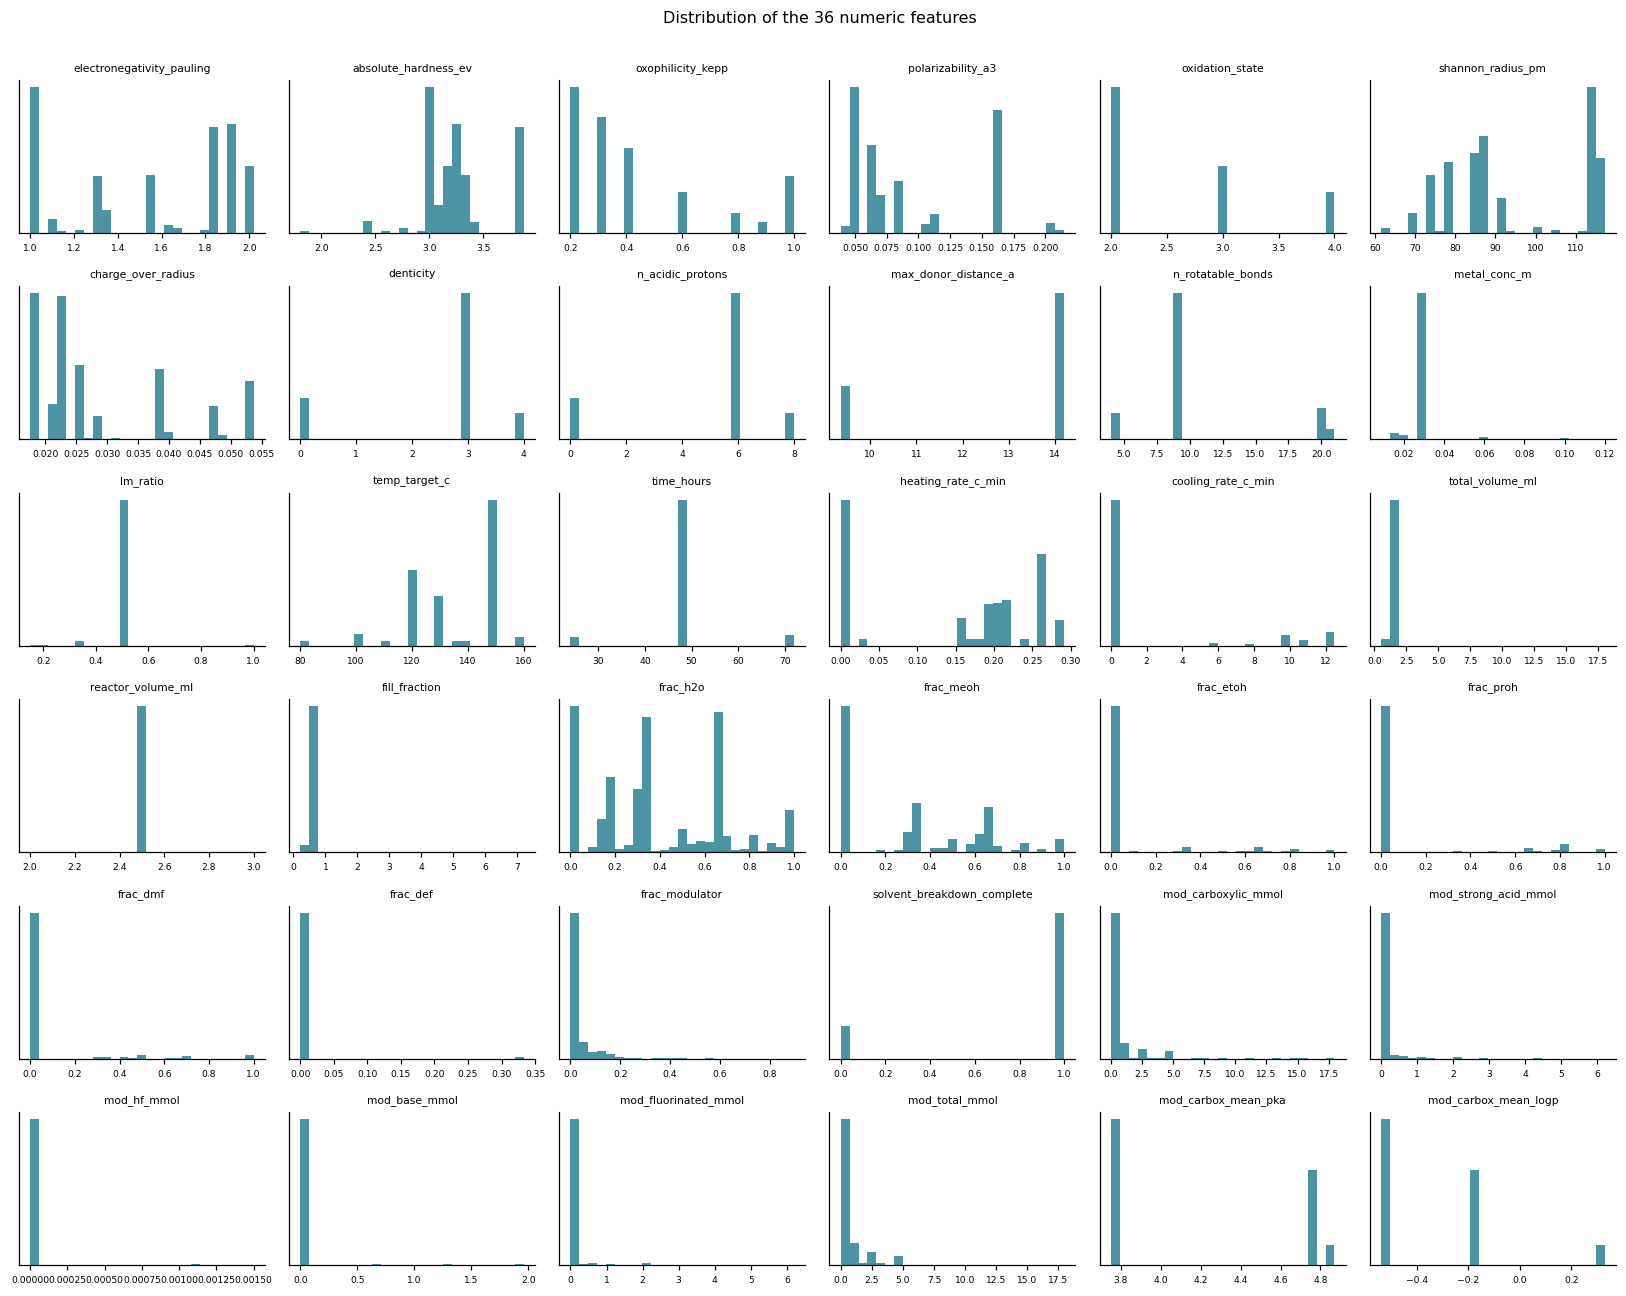

valores distintos: {'temp_target_c': 9, 'time_hours': 3, 'lm_ratio': 8, 'metal_conc_m': 10}


In [7]:
ID_COLS = ['sample_code', 'hts_number', 'synthesis_date', 'metal_center',
           'linker', 'metal_source', 'synthesis_type']
DROP_COLS = ['electronegativity_allen']          # no definida para lantanidos (5.3)
CAT_COLS = ['scaffold', 'protection_state']

dfn = df.copy()
dfn['solvent_breakdown_complete'] = dfn['solvent_breakdown_complete'].astype(float)
num_cols = [c for c in dfn.columns
            if c not in ID_COLS + DROP_COLS + CAT_COLS + ['ml_class']]
dfn[num_cols] = dfn[num_cols].apply(pd.to_numeric, errors='coerce')

ncol = 6
nrow = int(np.ceil(len(num_cols) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 1.95 * nrow))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(dfn[col].dropna(), bins=25, color=C_CRYS, alpha=0.8)
    ax.set_title(col, fontsize=7)
    ax.tick_params(labelsize=6); ax.set_yticks([]); ax.grid(False)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
fig.suptitle('Distribution of the %d numeric features' % len(num_cols), fontsize=10.5, y=1.003)
fig.tight_layout(); plt.show()

disc = {c: dfn[c].nunique() for c in
        ['temp_target_c', 'time_hours', 'lm_ratio', 'metal_conc_m'] if c in dfn}
print('valores distintos:', disc)

**Lo que hay que llevarse de aquí, y condiciona todo lo demás:** las variables de
proceso son **discretas de facto**. `temp_target_c` tiene ~13 valores distintos,
`time_hours` ~9, `lm_ratio` ~9.

(`lm_ratio` es la **relación molar ligando/metal teórica**, la columna `L/M` del Excel
maestro: rango 0,1–1,0 y mediana 0,50. Es de las pocas variables que se fijan
directamente al pesar, así que es **accionable** en el laboratorio.)

No es un defecto de los datos: refleja cómo se diseña de verdad la síntesis en
combinatoria — se fija una rejilla de condiciones y se barre composición. Pero tiene una
consecuencia que reaparecerá en §8.4: **una variable que apenas se varió no puede
explicar mucha varianza, por importante que sea químicamente.**

### 5.6 Correlación: dos preguntas distintas, y sólo una se suele dibujar

El mapa de correlación enfrenta cada variable con todas las demás y colorea la fuerza de
la relación **lineal**. Conviene ser preciso sobre qué se busca, porque es fácil leerlo
al revés.

**(1) ¿Se mueven juntas dos variables de *entrada*?** Lo que se busca **no es que la
correlación sea nula**: es *saber dónde no lo es*. Una correlación alta significa que dos
columnas aportan casi la misma información, con tres consecuencias:

- **Sobre la interpretación** (la más importante aquí). Si el radio iónico y la relación
  carga/radio van casi siempre juntas, el modelo repartirá el mérito entre ambas de forma
  arbitraria. Leer entonces "esta variable importa poco" sería un error: importa, pero su
  gemela se lleva el crédito. Por eso §8.4 interpreta **por bloques químicos**.
- **Sobre los modelos lineales.** La regresión logística se vuelve inestable con
  variables redundantes: coeficientes enormes y de signo caprichoso.
- **Sobre las fugas.** Correlación alta entre dos variables que no deberían tener
  relación suele delatar que una se derivó de la otra sin querer.

Un mapa con bloques rojos **no es un problema**: es información sobre la estructura del
experimento. Aquí los bloques rojos son, sobre todo, propiedades del mismo metal —
correlacionadas **por física**. La electronegatividad y la dureza de un catión no son
independientes en la naturaleza.

**(2) ¿Se relaciona cada variable con el *objetivo*?** *Esto* sí es lo que uno quiere alto
— es literalmente la señal que el modelo va a explotar. Pero Pearson no sirve: el
objetivo es categórico de tres niveles. Los equivalentes correctos son la **razón de
correlación η²** (numérica frente a categórica) y la **V de Cramér** (categórica frente a
categórica). Se dibujan las dos cosas.

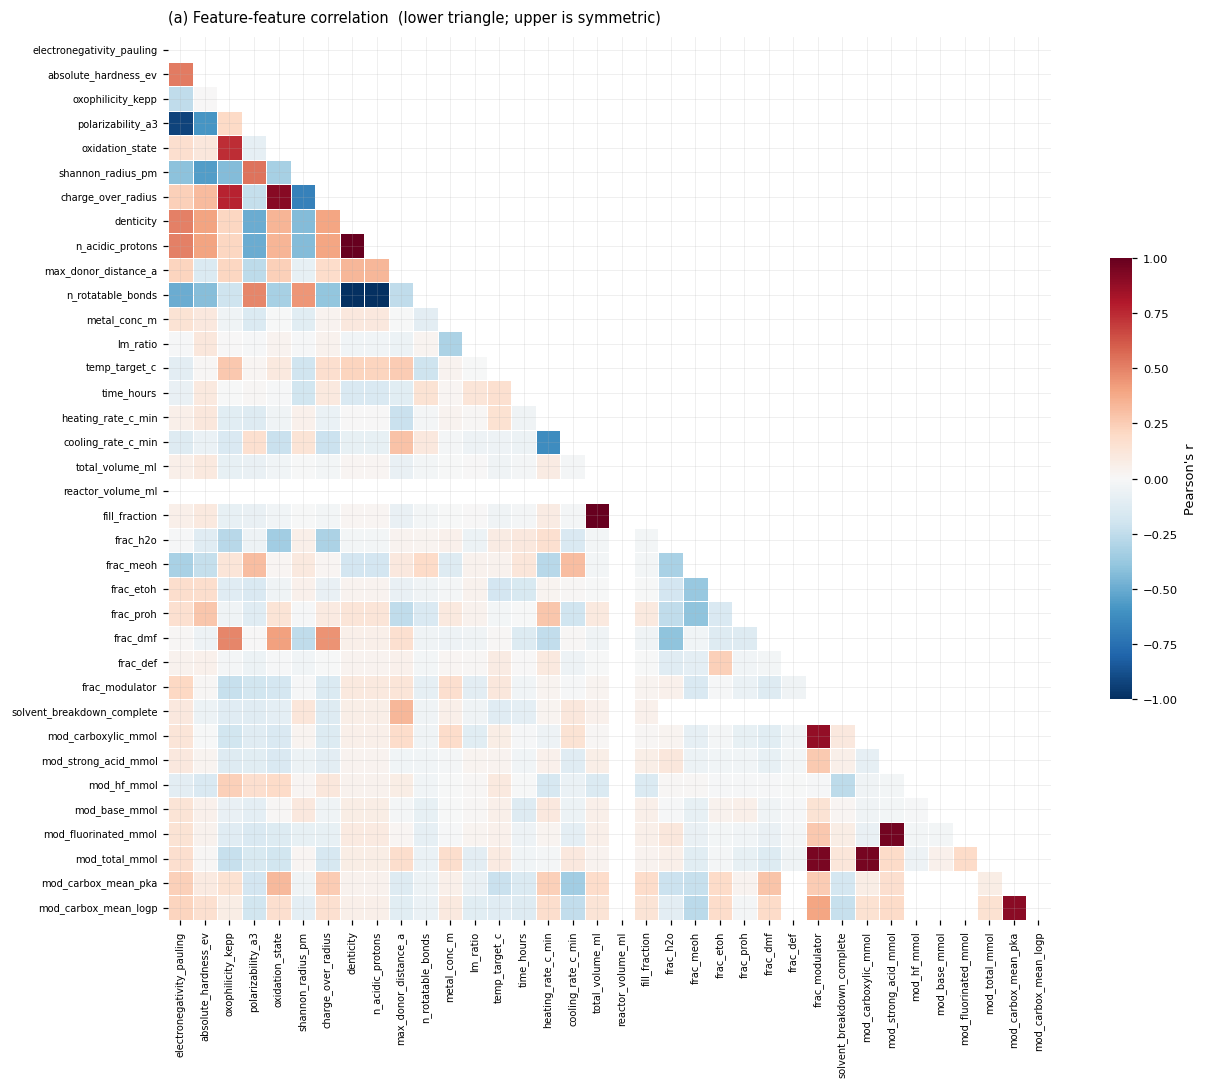

In [8]:
corr = dfn[num_cols].corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(12.5, 10))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.4, linecolor='white',
            cbar_kws={'shrink': 0.5, 'label': "Pearson's r"}, ax=ax)
ax.set_title('(a) Feature-feature correlation  (lower triangle; upper is symmetric)',
             loc='left', pad=10)
ax.tick_params(labelsize=6.5)
fig.tight_layout(); plt.show()

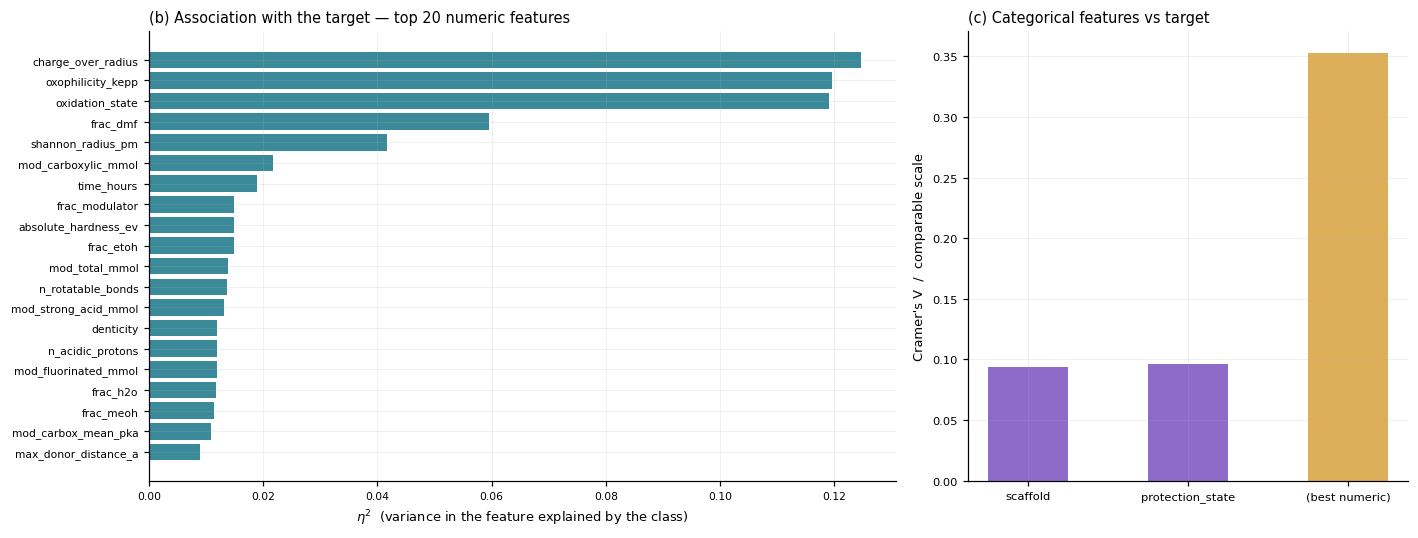

Las 8 variables mas asociadas con la clase (eta^2):
charge_over_radius     0.1247
oxophilicity_kepp      0.1196
oxidation_state        0.1190
frac_dmf               0.0596
shannon_radius_pm      0.0417
mod_carboxylic_mmol    0.0217
time_hours             0.0188
frac_modulator         0.0149

Categoricas (V de Cramer): {'scaffold': 0.094, 'protection_state': 0.096}


In [9]:
# (2) Asociacion de cada variable con el OBJETIVO.
# eta^2: fraccion de la varianza de la variable que explica la clase. 0 = ninguna.
def eta_cuadrado(x, clase):
    ok = x.notna()
    x, clase = x[ok], clase[ok]
    if x.nunique() < 2:
        return 0.0
    media = x.mean()
    entre = sum(len(g) * (g.mean() - media) ** 2 for _, g in x.groupby(clase))
    total = ((x - media) ** 2).sum()
    return float(entre / total) if total > 0 else 0.0

# V de Cramer: asociacion entre dos categoricas, normalizada a [0, 1]
def cramers_v(a, b):
    tab = pd.crosstab(a, b)
    chi2 = ((tab - np.outer(tab.sum(1), tab.sum(0)) / tab.values.sum()) ** 2
            / (np.outer(tab.sum(1), tab.sum(0)) / tab.values.sum())).values.sum()
    n = tab.values.sum()
    return float(np.sqrt((chi2 / n) / (min(tab.shape) - 1)))

aso = pd.Series({c: eta_cuadrado(dfn[c], df['ml_class']) for c in num_cols}
                ).sort_values(ascending=False)
aso_cat = {c: cramers_v(df[c], df['ml_class']) for c in CAT_COLS}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.7, 1]})
top = aso.head(20)[::-1]
axes[0].barh(top.index, top.values, color=C_CRYS, alpha=0.88)
axes[0].set_xlabel(r'$\eta^2$  (variance in the feature explained by the class)')
axes[0].set_title(r'(b) Association with the target — top 20 numeric features',
                  loc='left')
axes[0].tick_params(labelsize=7)

nombres = list(aso_cat) + ['(best numeric)']
valores = list(aso_cat.values()) + [np.sqrt(aso.max())]
axes[1].bar(nombres, valores, color=[C_INCI, C_INCI, C_AMOR], alpha=0.88, width=0.5)
axes[1].set_ylabel("Cramer's V  /  comparable scale")
axes[1].set_title('(c) Categorical features vs target', loc='left')
axes[1].tick_params(axis='x', labelsize=7.5)
fig.tight_layout(); plt.show()

print('Las 8 variables mas asociadas con la clase (eta^2):')
print(aso.head(8).round(4).to_string())
print('\nCategoricas (V de Cramer):', {k: round(v, 3) for k, v in aso_cat.items()})

**Cómo se lee (b).** η² responde: *de toda la variación de esta variable, ¿qué
fracción se explica sabiendo la clase?* Cero significa que la variable es idéntica en
amorfos y cristalinos — inútil por sí sola. Valores altos significan que la variable
**sí separa**.

Y aquí aparece el aviso que hay que repetir siempre:

> ⚠️ **Correlación no es causalidad.** Estos gráficos miden si dos cosas se mueven juntas,
> nada más. Que la temperatura aparezca asociada a la cristalinidad **no demuestra** que
> subirla cause cristalización: pueden compartir una causa común (las placas a más
> temperatura usaban además otro linker), o ser coincidencia del histórico. Establecer
> causalidad exige **intervenir** — cambiar sólo la temperatura y ver qué pasa —, que es
> precisamente lo que el modelo *sugiere dónde hacer*, no lo que demuestra.

Un corolario práctico: η² alto **no** significa "cambia esta variable y cristalizarás". La
lectura correcta es "esta variable distingue los casos que cristalizaron de los que no,
en este histórico".

### 5.7 ¿Separan las variables las clases? Vista bivariante

La asociación de §5.6 da un número por variable. Ahora la forma: **cómo** separa cada
una. Se eligen las de mayor η² más un par accionables en el laboratorio.

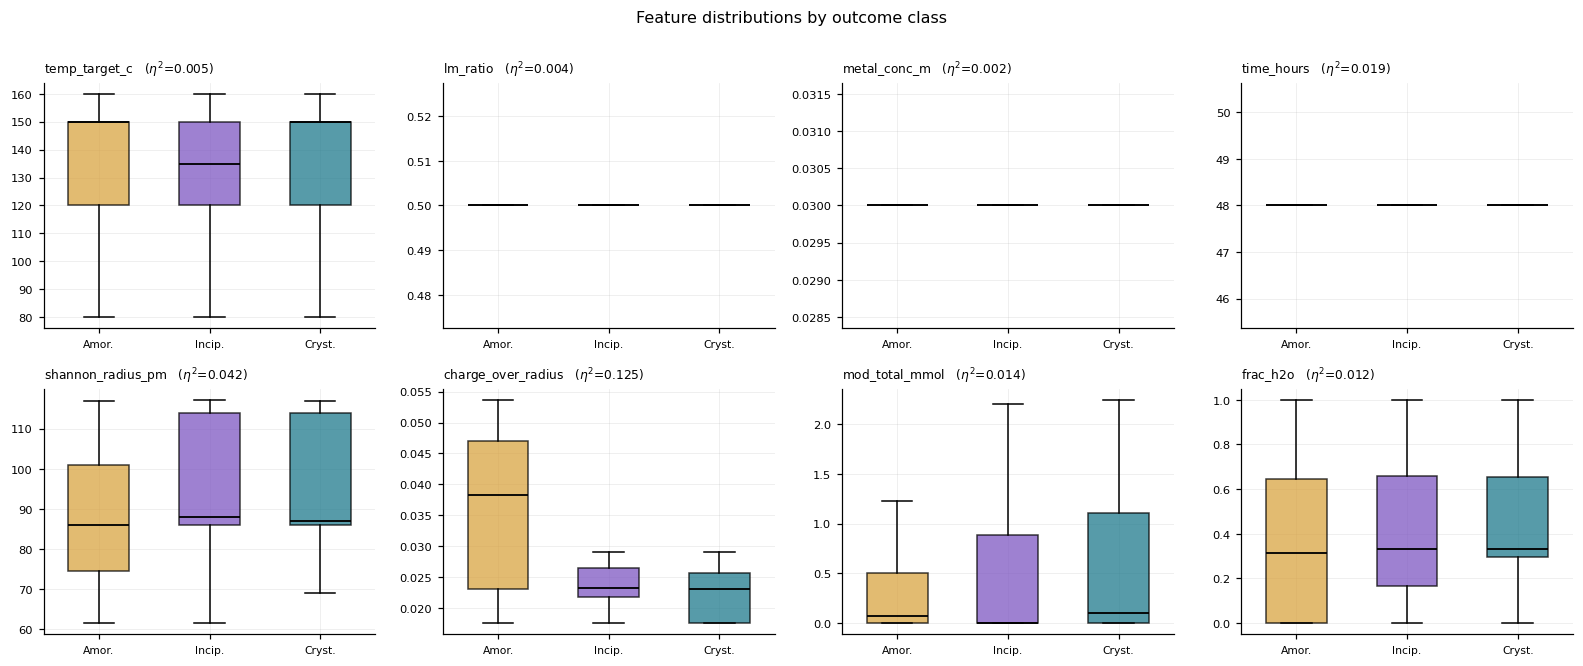

In [10]:
destacadas = [c for c in ['temp_target_c', 'lm_ratio', 'metal_conc_m', 'time_hours',
                          'shannon_radius_pm', 'charge_over_radius',
                          'mod_total_mmol', 'frac_h2o'] if c in dfn.columns]

fig, axes = plt.subplots(2, 4, figsize=(14.5, 6))
for ax, col in zip(axes.ravel(), destacadas):
    datos = [dfn.loc[df['ml_class'] == c, col].dropna() for c in CLASS_ORDER]
    bp = ax.boxplot(datos, patch_artist=True, widths=0.55, showfliers=False,
                    medianprops=dict(color='black', lw=1.2))
    for parche, c in zip(bp['boxes'], CLASS_ORDER):
        parche.set_facecolor(CLASS_COLORS[c]); parche.set_alpha(0.75)
    ax.set_xticklabels(['Amor.', 'Incip.', 'Cryst.'], fontsize=7)
    ax.set_title('%s   ($\\eta^2$=%.3f)' % (col, aso.get(col, 0)), fontsize=8, loc='left')
fig.suptitle('Feature distributions by outcome class', fontsize=10.5, y=1.002)
fig.tight_layout(); plt.show()

**Ninguna variable separa las clases por sí sola.** Las cajas se solapan en todas.
Eso no es malo: es la definición de un problema **multivariante**, y es exactamente la
razón por la que hace falta un modelo en vez de un umbral. Si una sola variable separase
limpiamente, no haría falta aprendizaje automático — bastaría una regla.

### 5.8 Estructura oculta: por qué una partición aleatoria mentiría

Esta subsección es la más importante del EDA, y la que un análisis apresurado se salta.
**Las filas de este conjunto no son independientes entre sí.**

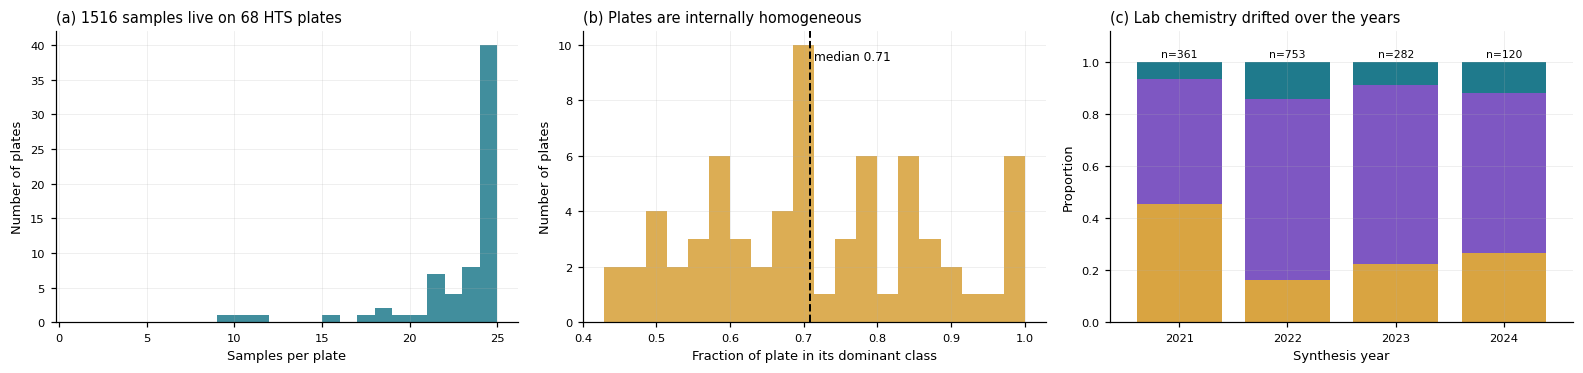

mediana de muestras por placa: 24
recuento por anio:
year
2021    361
2022    753
2023    282
2024    120


In [11]:
tam = df['hts_number'].value_counts()

fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.5))

axes[0].hist(tam.values, bins=range(1, int(tam.max()) + 2), color=C_CRYS, alpha=0.85)
axes[0].set_xlabel('Samples per plate'); axes[0].set_ylabel('Number of plates')
axes[0].set_title('(a) %d samples live on %d HTS plates' % (len(df), df['hts_number'].nunique()),
                  loc='left')

dom = df.groupby('hts_number')['ml_class'].agg(lambda s: s.value_counts().iloc[0] / len(s))
axes[1].hist(dom.values, bins=20, color=C_AMOR, alpha=0.9)
axes[1].axvline(dom.median(), color='black', ls='--', lw=1.3)
axes[1].text(dom.median(), axes[1].get_ylim()[1] * 0.9, ' median %.2f' % dom.median(), fontsize=8)
axes[1].set_xlabel('Fraction of plate in its dominant class')
axes[1].set_ylabel('Number of plates')
axes[1].set_title('(b) Plates are internally homogeneous', loc='left')

tmp = df.dropna(subset=['synthesis_date']).copy()
tmp['year'] = pd.to_datetime(tmp['synthesis_date']).dt.year
ct = pd.crosstab(tmp['year'], tmp['ml_class']).reindex(columns=CLASS_ORDER).fillna(0)
n_por_anio = ct.sum(axis=1)
(ct.div(n_por_anio, axis=0)).plot(kind='bar', stacked=True, ax=axes[2], width=0.78,
                                  color=[CLASS_COLORS[c] for c in CLASS_ORDER], legend=False)
for i, n in enumerate(n_por_anio.values):
    axes[2].text(i, 1.02, 'n=%d' % int(n), ha='center', fontsize=7)
axes[2].set_xlabel('Synthesis year'); axes[2].set_ylabel('Proportion'); axes[2].set_ylim(0, 1.12)
axes[2].set_title('(c) Lab chemistry drifted over the years', loc='left')
axes[2].tick_params(axis='x', rotation=0)
fig.tight_layout(); plt.show()

print('mediana de muestras por placa: %.0f' % tam.median())
print('recuento por anio:'); print(n_por_anio.astype(int).to_string())

**(a)** Las muestras vienen en **placas**: lotes preparados el mismo día, con el mismo
linker, la misma rampa y a menudo el mismo metal, barriendo una variable.

**(b)** Y las placas son **internamente homogéneas**: la mediana está muy alta, así que
conocer una muestra de una placa te dice casi el resultado de sus vecinas.

**La consecuencia es seria.** Una partición aleatoria pondría muestras de la *misma placa*
en entrenamiento y en prueba. El modelo no tendría que aprender química: le bastaría
reconocer la placa. **El resultado saldría inflado y sería falso.** Por eso §7.2 valida
con `StratifiedGroupKFold` agrupando por placa: ninguna placa aparece a la vez en los dos
lados.

**(c)** Además hay **deriva temporal**: la proporción de clases cambia por año, porque el
laboratorio fue aprendiendo. Los recuentos van anotados sobre cada barra a propósito —
una proporción sin su tamaño de muestra engaña. Un año con n=7 daría una barra al 100 %
que no significa nada.

### 5.9 Un vistazo global: proyección PCA

Antes de modelar, una última comprobación visual. **Es diagnóstico, no un modelo.**

#### Cómo se construye, en tres pasos

1. **Se estandarizan** las ~30 variables numéricas (media 0, desviación 1) tras imputar
   los ausentes. Sin esto, `time_hours` (hasta 96) aplastaría a `frac_h2o` (0–1) sólo por
   la escala de sus unidades, y el resultado mediría la elección de unidades en lugar de
   la química.
2. **Se busca la dirección de máxima varianza** en ese espacio de ~30 dimensiones. Esa
   dirección es una **combinación lineal de todas las variables** —no un subconjunto— y es
   la primera componente, **CP1**. Luego la de máxima varianza restante que sea
   **perpendicular** a la anterior: **CP2**. Y así.
3. **Se proyectan** las muestras sobre esas componentes para poder dibujarlas.

**Nada de esto "decide qué variables colapsar"**: el PCA las usa todas y, sobre todo,
**no conoce las clases** — es no supervisado. Los colores se pintan *encima*, después. Por
eso es un diagnóstico honesto: si las clases aparecen separadas, es estructura real de
las condiciones de síntesis, no algo que el método haya ido a buscar.

#### Sobre cuántas dimensiones enseñar

Se pueden codificar más de dos: color, símbolo, tamaño. Pero **cada codificación extra
cuesta atención del lector**, y el ojo humano estima el área muy mal — el tamaño como
quinta dimensión suele añadir ruido en vez de información. Aquí se usan **tres
codificaciones legibles** (CP1, CP2, color = clase) más una vista **3D con CP3**, y el
**símbolo para el esqueleto del linker**, que es lo que de verdad interesa comprobar: si
cada química ocupa su propia isla.

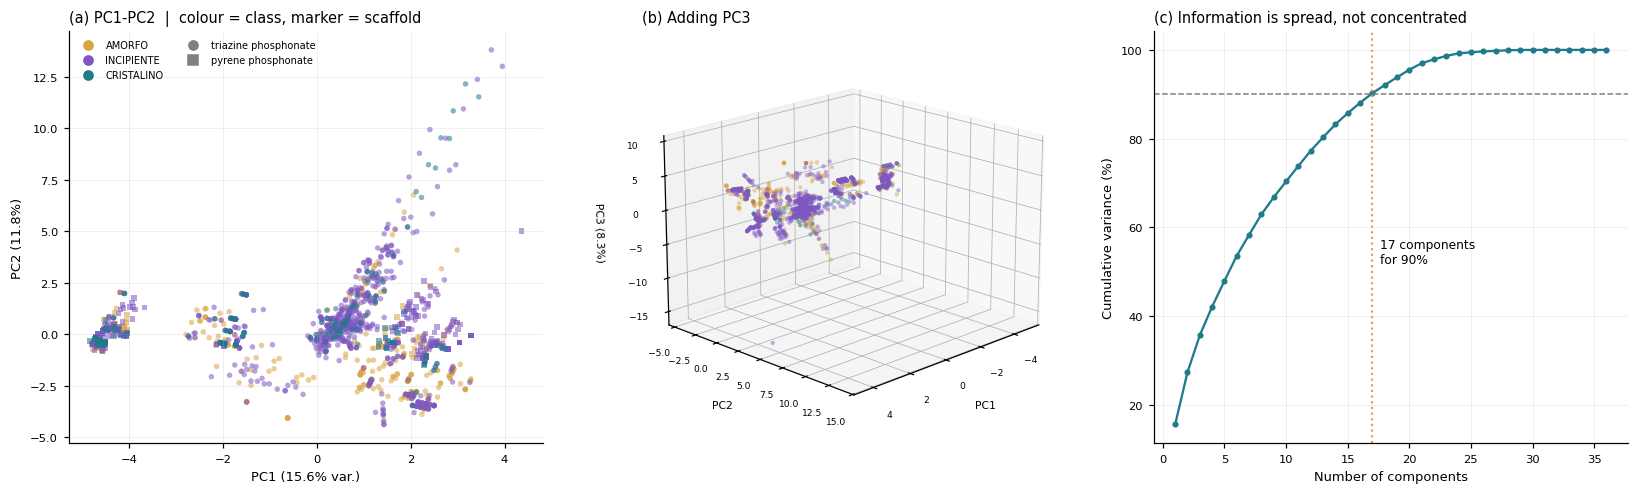

varianza de CP1-CP3: [15.6 11.8  8.3]  (suma 35.7%)


In [12]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

pca_pipe = Pipeline([('imp', SimpleImputer(strategy='median')),
                     ('sc', StandardScaler()),
                     ('pca', PCA(n_components=3, random_state=42))])
proj = pca_pipe.fit_transform(dfn[num_cols])
var = pca_pipe.named_steps['pca'].explained_variance_ratio_

MARCA = {'triazine_phosphonate': 'o', 'pyrene_phosphonate': 's',
         'polyphenol': '^', 'pyrene_bare': 'D'}

fig = plt.figure(figsize=(15, 4.6))
ax0 = fig.add_subplot(1, 3, 1)
for c in CLASS_ORDER:
    for sc, mk in MARCA.items():
        m = ((df['ml_class'] == c) & (df['scaffold'] == sc)).values
        if m.sum():
            ax0.scatter(proj[m, 0], proj[m, 1], s=13, alpha=0.55, marker=mk,
                        color=CLASS_COLORS[c], edgecolors='none')
ax0.set_xlabel('PC1 (%.1f%% var.)' % (100 * var[0]))
ax0.set_ylabel('PC2 (%.1f%%)' % (100 * var[1]))
ax0.set_title('(a) PC1-PC2  |  colour = class, marker = scaffold', loc='left')
from matplotlib.lines import Line2D
leg = [Line2D([], [], marker='o', ls='', color=CLASS_COLORS[c], label=c) for c in CLASS_ORDER]
leg += [Line2D([], [], marker=mk, ls='', color='grey', label=sc.replace('_', ' '))
        for sc, mk in MARCA.items() if (df['scaffold'] == sc).any()]
ax0.legend(handles=leg, fontsize=6.5, frameon=False, loc='best', ncol=2)

ax1 = fig.add_subplot(1, 3, 2, projection='3d')
for c in CLASS_ORDER:
    m = (df['ml_class'] == c).values
    ax1.scatter(proj[m, 0], proj[m, 1], proj[m, 2], s=8, alpha=0.45,
                color=CLASS_COLORS[c], edgecolors='none', label=c)
ax1.set_xlabel('PC1', fontsize=7); ax1.set_ylabel('PC2', fontsize=7)
ax1.set_zlabel('PC3 (%.1f%%)' % (100 * var[2]), fontsize=7)
ax1.tick_params(labelsize=6)
ax1.set_title('(b) Adding PC3', loc='left')
ax1.view_init(elev=18, azim=45)

pca_full = Pipeline([('imp', SimpleImputer(strategy='median')),
                     ('sc', StandardScaler()),
                     ('pca', PCA(random_state=42))]).fit(dfn[num_cols])
acum = np.cumsum(pca_full.named_steps['pca'].explained_variance_ratio_)
ax2 = fig.add_subplot(1, 3, 3)
ax2.plot(range(1, len(acum) + 1), 100 * acum, marker='o', ms=3, color=C_CRYS)
ax2.axhline(90, color='grey', ls='--', lw=1)
n90 = int(np.searchsorted(acum, 0.90) + 1)
ax2.axvline(n90, color=C_AMOR, ls=':', lw=1.4)
ax2.text(n90 + 0.6, 52, '%d components\nfor 90%%' % n90, fontsize=8)
ax2.set_xlabel('Number of components'); ax2.set_ylabel('Cumulative variance (%)')
ax2.set_title('(c) Information is spread, not concentrated', loc='left')
fig.tight_layout(); plt.show()

print('varianza de CP1-CP3: %s  (suma %.1f%%)'
      % (np.round(100 * var, 1), 100 * var[:3].sum()))

**(a)** Hay estructura, pero **las clases se solapan mucho**: confirma §5.7, el
problema es difícil y multivariante. El símbolo enseña además que los esqueletos ocupan
regiones distintas — la química del linker es una parte importante de lo que separa el
espacio.

**(b)** Añadir CP3 no revela una separación oculta. Es un resultado negativo útil: **no
hay un plano que separe las clases**, y eso ya adelanta que ningún modelo lineal va a
lucirse.

**(c)** Hacen falta bastantes componentes para el 90 % de la varianza: la información está
**repartida** entre muchas variables, no concentrada en dos o tres. Consecuencia práctica:
reducir dimensionalidad antes de modelar **tiraría señal**, así que **no se usa PCA en el
pipeline final** — sólo aquí, como diagnóstico.

---

# §6. Preparación de los datos (ETL)

> *Etapa 6 — Data Preparation. La etapa más larga de cualquier proyecto real, y la que
> nadie enseña. Aquí es, además, donde volvió el trabajo tras la revisión experta.*

Todo lo que sigue son correcciones sobre la base, hechas como parte de este análisis. No
son un efecto colateral: **son parte del rastro de razonamiento**, y por eso viven aquí.

### 6.1 Los siete defectos que encontró la revisión experta

La v2 de este cuaderno se dio por buena con F1 macro 0,62. Una lectura química de sus
tablas encontró siete problemas. **Ninguno había disparado ninguna alarma estadística.**

| # | Defecto | Cómo se detectó | Arreglo |
|---|---|---|---|
| **1** | Moduladores líquidos puros en **µmol etiquetados como mmol** (factor 1.000) | La mediana de ácido fórmico daba 1.168 «mmol» = **54 g en un reactor de 2,5 mL**: imposible | Fórmula corregida en el cuaderno 01 y valores divididos entre 1.000 |
| **2** | Al sumar mmol con µmol, **el HCl quedaba borrado** de `mod_strong_acid_mmol` | Consecuencia de (1): HCl ~0,004 frente a TFA ~600 | Unidades coherentes; el HCl vuelve a ser visible |
| **3** | **Tipo de síntesis ausente** como variable, siendo el mayor factor de confusión | Tabla de §5.0: MW 95,7 % cristalino vs HTS 11,0 % | Sólo HTS (§5.0) |
| **4** | **1-propanol y DEF fuera** de la tabla de características | Las fracciones de disolvente sumaban 0,789 en vez de 1 | Los seis disolventes en la vista |
| **5** | El **modulador líquido es a veces el disolvente**, y no se contaba como medio | Al arreglar (4) el volumen seguía sin cuadrar. RS1188: 1,35 mL de propiónico de 1,5 mL totales | `frac_modulator`, reconstruido desde los mmol |
| **6** | **HF agrupado con HCl** pese a su papel mineralizante distinto | Argumento químico: hay MOFs que sólo salen con HF | `mod_hf_mmol` separado |
| **7** | 22 filas sin radio iónico por un **espacio duro (U+00A0)** en el texto del precursor | `MgCl2 · 6H2O` no casaba con la tabla de mapeo | Emparejamiento **normalizado**, en vez de añadir variantes a mano |

**Y una corrección de fondo, más importante que las siete:** donde el desglose de
disolvente no explicaba el volumen total, las fracciones eran **0**. Ahora son **NULL**.

> Poner un 0 donde el dato es desconocido **no es neutro: es afirmar algo falso.** "Esta
> síntesis no llevaba metanol" y "no consta cuánto metanol llevaba" son cosas distintas, y
> el modelo no tiene forma de distinguirlas si se le da un 0. La bandera
> `solvent_breakdown_complete` deja el problema visible en vez de esconderlo.

In [13]:
# Comprobacion de que las correcciones estan aplicadas: la composicion del medio
# debe cerrar a 1 donde el desglose es completo.
comp = ['frac_h2o', 'frac_meoh', 'frac_etoh', 'frac_proh', 'frac_dmf', 'frac_def',
        'frac_modulator']
suma = df.loc[df['solvent_breakdown_complete'], comp].sum(axis=1)
print('Suma de las 7 fracciones del medio (desglose completo):')
print('   media %.4f   min %.4f   max %.4f   n=%d' %
      (suma.mean(), suma.min(), suma.max(), len(suma)))
print('\nDesglose completo: %d de %d filas (%.1f%%)'
      % (df['solvent_breakdown_complete'].sum(), len(df),
         100 * df['solvent_breakdown_complete'].mean()))

print('\nModuladores tras corregir las unidades (mmol, solo donde > 0):')
for c in ['mod_carboxylic_mmol', 'mod_strong_acid_mmol', 'mod_hf_mmol', 'mod_base_mmol']:
    s = pd.to_numeric(df[c], errors='coerce')
    if (s > 0).any():
        print('   %-24s n=%4d   mediana=%.4f   max=%.3f'
              % (c, (s > 0).sum(), s[s > 0].median(), s.max()))

Suma de las 7 fracciones del medio (desglose completo):
   media 0.9987   min 0.9501   max 1.0001   n=1238

Desglose completo: 1238 de 1516 filas (81.7%)

Moduladores tras corregir las unidades (mmol, solo donde > 0):
   mod_carboxylic_mmol      n= 456   mediana=1.1194   max=17.965
   mod_strong_acid_mmol     n= 426   mediana=0.1002   max=6.200
   mod_hf_mmol              n=  25   mediana=0.0011   max=0.002
   mod_base_mmol            n=  27   mediana=1.3072   max=1.961


**La composición del medio cierra a 1,000.** Antes de la corrección la media era
0,789. Es la comprobación que demuestra que (4) y (5) están de verdad arreglados — y el
tipo de comprobación que la v2 no tenía, que es justamente por qué el fallo sobrevivió.

### 6.2 Unicidad, duplicados y óxidos: exclusión como etiqueta, nunca como borrado

El EDA de la v2 destapó que contar *filas* daba más que contar `sample_code` distintos:
**43 muestras tenían más de una medida PXRD etiquetada por separado** (una recién sacada
y otra lavada, un refinamiento…). Dejarlas habría metido la misma muestra física varias
veces — el mismo problema de fuga de §5.8, pero a nivel de muestra.

Se revisaron las 43 una a una en `app/pxrd_explorer.py`, eligiendo con qué medida
quedarse. Y con el mismo mecanismo se excluyeron **70 medidas AMORFO con reflexiones
intensas de óxido**: la revisión experta confirmó que meterlas como "amorfo" contaminaría
la clase, porque el difractograma muestra cristalinidad — de un óxido que no es el
producto buscado.

**Se marcaron, no se borraron.** Las etiquetas descartadas son juicio humano real sobre un
fichero real, así que en vez de eliminarlas se escribió una etiqueta nueva
`ml_include = 'NO'`. La exclusión es **reversible y auditada**; la ausencia de esa
etiqueta significa "incluida". Es una idea que merece generalizarse: **en un almacén de
datos científicos, borrar destruye evidencia; etiquetar la conserva.**

### 6.3 El ácido tánico: una decisión química, confirmada con una medida

24 muestras del conjunto usaban **ácido tánico**, un polifenol. Es la **única química no
fosfonato** del histórico, y su denticidad no está bien definida (tiene ~25 OH fenólicos:
no hay un número de "dientes" que tenga sentido).

**El argumento para excluirlas es químico y va primero:** 24 muestras no bastan para que
un modelo aprenda una familia química distinta, y su presencia obliga a los descriptores
de linker a describir dos cosas incompatibles a la vez.

La medida lo confirma: retirarlas sube el F1 macro del mejor modelo de **0,495 a 0,527** y
el MCC de 0,266 a 0,312.

> ⚠️ **Una cautela metodológica que hay que decir en voz alta.** Elegir qué datos quitar
> *porque sube la métrica* es una forma de hacer trampa: siempre se puede subir el número
> quitando los casos difíciles. Aquí el orden fue el correcto — **primero el argumento
> químico, después la comprobación** — y por eso la exclusión es legítima. Si el criterio
> hubiera sido "probemos a quitar cosas a ver qué sube", el resultado no valdría nada.

### 6.4 Imputación: probada, no supuesta

Quedan ausentes (§5.3). Se imputa por la **mediana** las numéricas y por la **moda** las
categóricas, siempre **dentro del pipeline de validación cruzada** — nunca antes.

> Esto último no es un detalle. Imputar con la mediana de *todo* el conjunto antes de
> partir en entrenamiento y prueba filtra información del segundo al primero: la mediana
> del conjunto de prueba habría participado en el cálculo. Es una **fuga sutil** que infla
> el resultado sin que nada falle. Dentro del pipeline, cada pliegue calcula su mediana
> con sus datos y sólo con los suyos.

**Se probó la alternativa** de marcar explícitamente los ausentes (`add_indicator`), que
permitiría al modelo aprender de *que falte* un dato:

| | F1 macro | MCC |
|---|---:|---:|
| Random Forest, imputación simple | 0,496 | 0,274 |
| Random Forest, **marcando el ausente** | 0,495 | 0,266 |
| SVM, imputación simple | 0,471 | 0,275 |
| SVM, **marcando el ausente** | 0,458 | 0,258 |

**No aporta nada**, así que se queda la versión simple. Merece registrarse justamente por
eso: la decisión está *comprobada*, no supuesta, y saber que la ausencia **no** es
informativa es en sí un resultado — significa que los huecos son accidentes de registro y
no un patrón con significado químico.

---

# §7. Modelado

> *Etapa 7 — Modeling. Con el problema bien planteado y los datos preparados, esta etapa
> es sorprendentemente corta. Ese es el orden correcto.*

### 7.1 El diseño experimental

**Se prueban 10 modelos, no uno.** No por indecisión: porque las familias de modelos
asumen cosas distintas sobre la forma de la frontera entre clases, y con un problema
nuevo no se sabe de antemano cuál asume lo correcto. Comparar es más honesto que apostar.

| Modelo | Qué asume / cómo decide | Por qué está aquí |
|---|---|---|
| **Baseline (mayoritaria)** | Nada: siempre la clase más frecuente | **El listón**. Todo lo demás debe batirlo |
| **Regresión logística** | Frontera lineal | Referencia interpretable; si basta, ganó |
| **KNN** | Las muestras parecidas comparten resultado | Puramente local, sin modelo global |
| **Naive Bayes** | Variables independientes dada la clase | Su fallo mide cuánto importa la correlación de §5.6 |
| **SVM (RBF)** | Frontera suave no lineal | Fuerte en dimensión media con pocos datos |
| **Árbol de decisión** | Cortes por umbral, uno a uno | Interpretable; base de lo que viene |
| **Random Forest** | Muchos árboles decorrelacionados | Robusto, poco sensible a hiperparámetros |
| **HistGradientBoosting** | Árboles secuenciales que corrigen errores | Maneja ausentes **de forma nativa** |
| **LightGBM** | Boosting optimizado | Referencia del sector |
| **XGBoost** | Boosting con regularización | Comparación estándar |

Todos los que lo permiten llevan `class_weight='balanced'`, que compensa el desequilibrio
5,8:1 de §5.4 penalizando más los errores en las clases minoritarias.

### 7.2 La validación: agrupada por placa, como exige §5.8

`StratifiedGroupKFold` con 5 pliegues hace dos cosas a la vez:

- **Group**: ninguna placa aparece a la vez en entrenamiento y en prueba. Sin esto, el
  modelo aprobaría reconociendo la placa en vez de la química.
- **Stratified**: cada pliegue mantiene la proporción de clases, para que ningún pliegue
  se quede casi sin cristalinos.

### 7.3 Dos modelos, no uno: el completo y el accionable

Aquí se responde a una objeción de fondo que planteó la revisión, y que **es una crítica
al planteamiento del problema**, no a la ejecución:

> *El linker no hace que un metal cristalice; el linker determina **qué material puede
> llegar a existir**. Cambiarlo no es mover una condición de reacción: es cambiar de
> química.*

Es correcto, y tiene consecuencias. Las variables se dividen en dos tipos:

| Tipo | Variables | ¿Se puede actuar sobre ellas? |
|---|---|---|
| **De diseño / identidad** | Química del linker y del metal | Sí, pero cambiarlas **cambia el objetivo de la investigación** |
| **De proceso / medio** | [M], L/M, temperatura, tiempo, rampas, moduladores, disolventes | Sí, **dentro de la misma química** |

Un modelo que diga "usa H8ptp" no está dando un consejo accionable: está diciendo
"investiga otro material". Así que se entrenan **dos**:

1. **Modelo completo** → responde *"¿hay señal predictiva en estos datos?"*
2. **Modelo accionable** (sin química de metal ni de linker) → responde *"dada esta
   química, ¿qué condiciones la hacen cristalizar?"*, que es la pregunta que sirve para
   diseñar la próxima placa.

La diferencia entre los dos es, en sí misma, un resultado.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, GroupShuffleSplit
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

y = df['ml_class']
X = dfn[num_cols + CAT_COLS].copy()
# La placa es el GRUPO de validacion, nunca una entrada del modelo
groups = df['hts_number'].where(df['hts_number'] != 'N/A', df['sample_code'])

print('X: %d filas x %d variables   |   grupos (placas): %d'
      % (X.shape[0], X.shape[1], groups.nunique()))


def preprocesador(escalar, cols_num, cols_cat):
    pasos = [('imp', SimpleImputer(strategy='median'))]
    if escalar:
        pasos.append(('sc', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(pasos), cols_num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore'))]), cols_cat)])


MODELOS = {
    'Baseline (mayoritaria)': (DummyClassifier(strategy='most_frequent'), False),
    'Regresion logistica':    (LogisticRegression(max_iter=3000, class_weight='balanced'), True),
    'KNN (k=15)':             (KNeighborsClassifier(n_neighbors=15), True),
    'Naive Bayes':            (GaussianNB(), True),
    'SVM (RBF)':              (SVC(class_weight='balanced'), True),
    'Arbol de decision':      (DecisionTreeClassifier(max_depth=6, class_weight='balanced',
                                                     random_state=42), False),
    'Random Forest':          (RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                                                     class_weight='balanced_subsample',
                                                     random_state=42, n_jobs=-1), False),
    'HistGradientBoosting':   (HistGradientBoostingClassifier(random_state=42), False),
    'LightGBM':               (LGBMClassifier(n_estimators=400, learning_rate=0.05,
                                              class_weight='balanced', random_state=42,
                                              verbose=-1), False),
    'XGBoost':                (XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5,
                                             tree_method='hist', random_state=42,
                                             verbosity=0), False),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
METRICAS = ['f1_macro', 'balanced_accuracy', 'matthews_corrcoef', 'accuracy']
le = LabelEncoder(); y_enc = le.fit_transform(y)


def comparar(Xd, etiqueta):
    cn = [c for c in Xd.columns if c not in CAT_COLS]
    cc = [c for c in Xd.columns if c in CAT_COLS]
    filas = []
    for nombre, (est, escalar) in MODELOS.items():
        yy = y_enc if nombre == 'XGBoost' else y
        pipe = Pipeline([('prep', preprocesador(escalar, cn, cc)), ('clf', est)])
        r = cross_validate(pipe, Xd, yy, groups=groups, cv=cv, scoring=METRICAS, n_jobs=1)
        filas.append({'modelo': nombre,
                      'F1 macro': r['test_f1_macro'].mean(),
                      'sd': r['test_f1_macro'].std(),
                      'Exact. equil.': r['test_balanced_accuracy'].mean(),
                      'MCC': r['test_matthews_corrcoef'].mean(),
                      'Exactitud': r['test_accuracy'].mean()})
    return (pd.DataFrame(filas).sort_values('F1 macro', ascending=False)
              .reset_index(drop=True))


res_completo = comparar(X, 'completo')
res_completo.round(3)

X: 1516 filas x 38 variables   |   grupos (placas): 68


,modelo,F1 macro,sd,Exact. equil.,MCC,Exactitud
0,Random Forest,0.522,0.049,0.530,0.309,0.632
1,LightGBM,0.496,0.075,0.501,0.258,0.611
2,SVM (RBF),0.470,0.038,0.512,0.260,0.537
3,HistGradientBoosting,0.463,0.077,0.458,0.236,0.645
4,XGBoost,0.460,0.071,0.453,0.242,0.648
5,Regresion logistica,0.446,0.066,0.517,0.217,0.484
6,KNN (k=15),0.419,0.033,0.429,0.238,0.660
7,Arbol de decision,0.371,0.073,0.443,0.134,0.407
8,Baseline (mayoritaria),0.259,0.013,0.333,0.000,0.637
9,Naive Bayes,0.226,0.057,0.409,0.104,0.211


In [15]:
COLS_LINKER = ['scaffold', 'protection_state', 'denticity', 'n_acidic_protons',
               'max_donor_distance_a', 'n_rotatable_bonds']
COLS_METAL = ['electronegativity_pauling', 'absolute_hardness_ev', 'oxophilicity_kepp',
              'polarizability_a3', 'oxidation_state', 'shannon_radius_pm',
              'charge_over_radius']

X_accionable = X.drop(columns=[c for c in COLS_LINKER + COLS_METAL if c in X.columns])
print('Modelo accionable: %d variables (solo proceso y medio)' % X_accionable.shape[1])
print(sorted(X_accionable.columns.tolist()))

res_accionable = comparar(X_accionable, 'accionable')
res_accionable.round(3)

Modelo accionable: 25 variables (solo proceso y medio)
['cooling_rate_c_min', 'fill_fraction', 'frac_def', 'frac_dmf', 'frac_etoh', 'frac_h2o', 'frac_meoh', 'frac_modulator', 'frac_proh', 'heating_rate_c_min', 'lm_ratio', 'metal_conc_m', 'mod_base_mmol', 'mod_carbox_mean_logp', 'mod_carbox_mean_pka', 'mod_carboxylic_mmol', 'mod_fluorinated_mmol', 'mod_hf_mmol', 'mod_strong_acid_mmol', 'mod_total_mmol', 'reactor_volume_ml', 'solvent_breakdown_complete', 'temp_target_c', 'time_hours', 'total_volume_ml']


,modelo,F1 macro,sd,Exact. equil.,MCC,Exactitud
0,LightGBM,0.413,0.064,0.435,0.133,0.530
1,Random Forest,0.396,0.040,0.418,0.133,0.542
2,SVM (RBF),0.369,0.056,0.399,0.093,0.436
3,KNN (k=15),0.365,0.032,0.387,0.135,0.612
4,XGBoost,0.359,0.062,0.378,0.097,0.606
5,Regresion logistica,0.358,0.026,0.409,0.075,0.418
6,HistGradientBoosting,0.341,0.041,0.364,0.064,0.587
7,Arbol de decision,0.298,0.024,0.406,0.060,0.317
8,Baseline (mayoritaria),0.259,0.013,0.333,0.000,0.637
9,Naive Bayes,0.195,0.054,0.388,0.081,0.187


---

# §8. Evaluación

> *Etapa 8 — Evaluation. No "¿qué número sale?" sino "¿es este número creíble, y qué
> significa para el laboratorio?".*

### 8.1 Las métricas, y por qué la exactitud engaña aquí

| Métrica | Qué mide | Por qué está |
|---|---|---|
| **F1 macro** | Media del F1 de cada clase, **dando el mismo peso a las tres** | La métrica principal. Ignorar los 167 cristalinos la hunde |
| **Exactitud equilibrada** | Media del acierto **dentro de** cada clase | Directamente interpretable: "acierta X % de los cristalinos" |
| **MCC** | Correlación entre predicción y verdad, −1 a +1 | La más exigente: 0 = azar, aunque la exactitud sea alta |
| **Exactitud** | % de aciertos | **Sólo como aviso**: la línea base ya saca ~64 % |

> Recordatorio de §2: **MRE, RMSE y R² no aplican** — son de regresión, miden distancia a
> un número. En clasificación o aciertas la clase o no.

In [16]:
def resaltar(t):
    return (t.style.format({'F1 macro': '{:.3f}', 'sd': '{:.3f}', 'Exact. equil.': '{:.3f}',
                            'MCC': '{:.3f}', 'Exactitud': '{:.3f}'})
             .background_gradient(subset=['F1 macro', 'MCC'], cmap='Blues'))

base = res_completo.loc[res_completo['modelo'].str.startswith('Baseline'), 'F1 macro'].iloc[0]
mejor_c = res_completo.iloc[0]
mejor_a = res_accionable.iloc[0]

print('LINEA BASE          F1 macro = %.3f' % base)
print('MODELO COMPLETO     F1 macro = %.3f  (%s)   MCC = %.3f'
      % (mejor_c['F1 macro'], mejor_c['modelo'], mejor_c['MCC']))
print('MODELO ACCIONABLE   F1 macro = %.3f  (%s)   MCC = %.3f'
      % (mejor_a['F1 macro'], mejor_a['modelo'], mejor_a['MCC']))
resaltar(res_completo)

LINEA BASE          F1 macro = 0.259
MODELO COMPLETO     F1 macro = 0.522  (Random Forest)   MCC = 0.309
MODELO ACCIONABLE   F1 macro = 0.413  (LightGBM)   MCC = 0.133


,modelo,F1 macro,sd,Exact. equil.,MCC,Exactitud
0,Random Forest,0.522,0.049,0.530,0.309,0.632
1,LightGBM,0.496,0.075,0.501,0.258,0.611
2,SVM (RBF),0.470,0.038,0.512,0.260,0.537
3,HistGradientBoosting,0.463,0.077,0.458,0.236,0.645
4,XGBoost,0.460,0.071,0.453,0.242,0.648
5,Regresion logistica,0.446,0.066,0.517,0.217,0.484
6,KNN (k=15),0.419,0.033,0.429,0.238,0.660
7,Arbol de decision,0.371,0.073,0.443,0.134,0.407
8,Baseline (mayoritaria),0.259,0.013,0.333,0.000,0.637
9,Naive Bayes,0.226,0.057,0.409,0.104,0.211


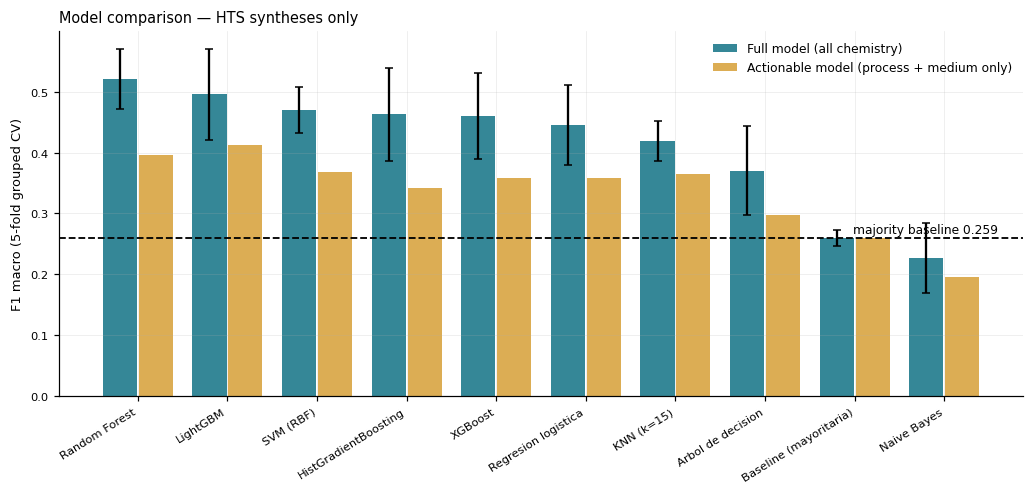

In [17]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
orden = res_completo['modelo'].tolist()
xx = np.arange(len(orden))
f_c = res_completo.set_index('modelo').loc[orden, 'F1 macro'].values
sd_c = res_completo.set_index('modelo').loc[orden, 'sd'].values
f_a = res_accionable.set_index('modelo').loc[orden, 'F1 macro'].values

ax.bar(xx - 0.2, f_c, 0.38, yerr=sd_c, capsize=2.5, color=C_CRYS, alpha=0.9,
       label='Full model (all chemistry)')
ax.bar(xx + 0.2, f_a, 0.38, color=C_AMOR, alpha=0.9,
       label='Actionable model (process + medium only)')
ax.axhline(base, color='black', ls='--', lw=1.2)
ax.text(len(orden) - 0.4, base + 0.008, 'majority baseline %.3f' % base,
        ha='right', fontsize=8)
ax.set_xticks(xx); ax.set_xticklabels(orden, rotation=32, ha='right', fontsize=7.5)
ax.set_ylabel('F1 macro (5-fold grouped CV)')
ax.set_title('Model comparison — HTS syntheses only', loc='left')
ax.legend(frameon=False, loc='upper right')
fig.tight_layout(); plt.show()

### 8.2 Qué dicen estos números

**1. Hay señal predictiva real, y es más modesta de lo que parecía.** El mejor modelo
completo llega a **F1 macro ≈ 0,52** frente a **0,26** de la línea base: el doble. Con
MCC ≈ 0,31, que es una asociación real pero lejos de fuerte.

**2. El 0,62 de la versión anterior no era verdad.** La bajada de 0,62 a 0,52 es
exactamente lo que costaba quitar el microondas y la solvotermal estándar — es decir, la
parte del acierto que venía de detectar el **método** en vez de la química. Es
incómodo y es el resultado más valioso del cuaderno.

**3. El modelo accionable baja bastante más, y eso responde a la objeción de §7.3.**
Quitando la química de metal y linker, el mejor modelo cae a ~0,41 con **MCC ≈ 0,13** —
por encima del azar, pero débil.

> **Traducción química, dicha sin adornos:** en este histórico, **la mayor parte de lo que
> el modelo distingue es qué sistema metal-linker se usó, no qué condiciones se
> aplicaron**. Las condiciones de proceso aportan algo, pero poco.
>
> Esto **no** significa que las condiciones no importen químicamente. Significa que *en
> estos datos* no se variaron lo suficiente como para que su efecto sea aprendible
> (§5.5: ~13 temperaturas, ~9 tiempos). La sospecha de que el linker estaba haciendo de
> variable directora era **correcta**, y ahora está medida.

**4. Los modelos de árboles ganan ahora.** En la v2, con las variables sucias, ganaban KNN
y SVM. Con las variables corregidas, Random Forest y LightGBM pasan al frente. Es
coherente: los métodos que construyen fronteras a base de umbrales se benefician de que
las variables signifiquen de verdad lo que dicen.

**5. Naive Bayes se hunde por debajo de la línea base.** No es un fallo de la
implementación: es que asume que las variables son independientes dada la clase, y §5.6
mostró bloques de correlación fuertes. **Su fracaso es una medida de cuánto importa esa
correlación** — por eso está en la lista.

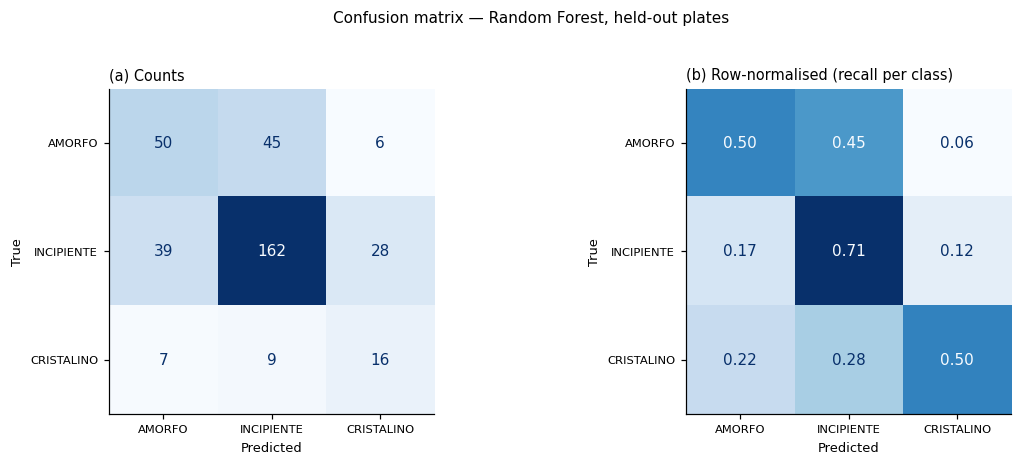

              precision    recall  f1-score   support

      AMORFO      0.521     0.495     0.508       101
  INCIPIENTE      0.750     0.707     0.728       229
  CRISTALINO      0.320     0.500     0.390        32

    accuracy                          0.630       362
   macro avg      0.530     0.567     0.542       362
weighted avg      0.648     0.630     0.637       362



In [18]:
from sklearn.metrics import (confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

nombre_mejor = res_completo.iloc[0]['modelo']
est_mejor, escalar_mejor = MODELOS[nombre_mejor]

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
itr, ite = next(gss.split(X, y, groups=groups))
X_tr, X_te = X.iloc[itr], X.iloc[ite]
y_tr, y_te = y.iloc[itr], y.iloc[ite]

cn = [c for c in X.columns if c not in CAT_COLS]
cc = [c for c in X.columns if c in CAT_COLS]
mejor = Pipeline([('prep', preprocesador(escalar_mejor, cn, cc)),
                  ('clf', est_mejor)]).fit(X_tr, y_tr)
pred = mejor.predict(X_te)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.1))
for ax, norm, tit in [(axes[0], None, '(a) Counts'),
                      (axes[1], 'true', '(b) Row-normalised (recall per class)')]:
    cm = confusion_matrix(y_te, pred, labels=CLASS_ORDER, normalize=norm)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_ORDER).plot(
        ax=ax, cmap='Blues', colorbar=False,
        values_format='d' if norm is None else '.2f')
    ax.set_title(tit, loc='left'); ax.grid(False)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
fig.suptitle('Confusion matrix — %s, held-out plates' % nombre_mejor, fontsize=10, y=1.02)
fig.tight_layout(); plt.show()

print(classification_report(y_te, pred, labels=CLASS_ORDER, digits=3))

In [19]:
# Confundir clases VECINAS no es lo mismo que confundir los EXTREMOS: la etiqueta
# es ordinal (amorfo < incipiente < cristalino). Se mide la diferencia.
cm = confusion_matrix(y_te, pred, labels=CLASS_ORDER)
idx = {c: i for i, c in enumerate(CLASS_ORDER)}
tot = {c: cm[idx[c]].sum() for c in CLASS_ORDER}

extremos = cm[idx['AMORFO'], idx['CRISTALINO']] + cm[idx['CRISTALINO'], idx['AMORFO']]
n_ext = tot['AMORFO'] + tot['CRISTALINO']
print('Errores AMORFO <-> CRISTALINO (los extremos): %d de %d muestras de esas clases (%.1f%%)'
      % (extremos, n_ext, 100 * extremos / n_ext))
print('  AMORFO clasificado CRISTALINO: %d de %d (%.1f%%)'
      % (cm[idx['AMORFO'], idx['CRISTALINO']], tot['AMORFO'],
         100 * cm[idx['AMORFO'], idx['CRISTALINO']] / tot['AMORFO']))
print('  CRISTALINO clasificado AMORFO: %d de %d (%.1f%%)'
      % (cm[idx['CRISTALINO'], idx['AMORFO']], tot['CRISTALINO'],
         100 * cm[idx['CRISTALINO'], idx['AMORFO']] / tot['CRISTALINO']))
print('\nConfusion con la clase VECINA (INCIPIENTE):')
print('  AMORFO -> INCIPIENTE: %d de %d (%.1f%%)'
      % (cm[idx['AMORFO'], idx['INCIPIENTE']], tot['AMORFO'],
         100 * cm[idx['AMORFO'], idx['INCIPIENTE']] / tot['AMORFO']))
print('  CRISTALINO -> INCIPIENTE: %d de %d (%.1f%%)'
      % (cm[idx['CRISTALINO'], idx['INCIPIENTE']], tot['CRISTALINO'],
         100 * cm[idx['CRISTALINO'], idx['INCIPIENTE']] / tot['CRISTALINO']))

Errores AMORFO <-> CRISTALINO (los extremos): 13 de 133 muestras de esas clases (9.8%)
  AMORFO clasificado CRISTALINO: 6 de 101 (5.9%)
  CRISTALINO clasificado AMORFO: 7 de 32 (21.9%)

Confusion con la clase VECINA (INCIPIENTE):
  AMORFO -> INCIPIENTE: 45 de 101 (44.6%)
  CRISTALINO -> INCIPIENTE: 9 de 32 (28.1%)


### 8.3 Dónde se equivoca: los errores tienen sentido químico

La matriz de confusión dice mucho más que una métrica. Lo importante no es *cuánto* falla
sino **hacia dónde**.

Los números impresos arriba obligan a matizar, y conviene hacerlo en vez de contar la
versión bonita. **El patrón ordinal se cumple con claridad en una dirección y sólo a
medias en la otra:**

| Clase real | → clase vecina (INCIPIENTE) | → extremo opuesto |
|---|---:|---:|
| **AMORFO** | 44,6 % | **5,9 %** hacia CRISTALINO |
| **CRISTALINO** | 28,1 % | **21,9 %** hacia AMORFO |

**Para el amorfo, el comportamiento es el esperado:** cuando falla, confunde "nada" con
"casi nada", que en el propio difractograma es cuestión de grado y sobre lo que dos
personas expertas podrían discrepar. El error grave —llamar cristalino a un amorfo— es
raro (5,9 %).

**Para el cristalino, no.** Uno de cada cinco cristalinos se clasifica como **amorfo**, el
error más grave posible. Eso no es un patrón ordinal limpio: es que el modelo **no
reconoce bien la clase minoritaria**, y cuando la pierde la pierde del todo. Con 167 casos
frente a 967 incipientes, y siendo la clase más heterogénea —hay muchas formas de
cristalizar y sólo una de no hacerlo—, era el resultado previsible, pero no por previsible
deja de ser la debilidad principal del modelo.

**Qué significa para el uso previsto.** Para §9 —ordenar candidatos y llenar una placa—
importa menos de lo que parece: lo que se necesita es que los buenos candidatos suban en
el ranking, no que la etiqueta sea exacta. Pero desmiente cualquier lectura del tipo "el
modelo casi nunca se equivoca de forma grave". **Se equivoca de forma grave en el 22 % de
los cristalinos**, y con eso hay que contar.

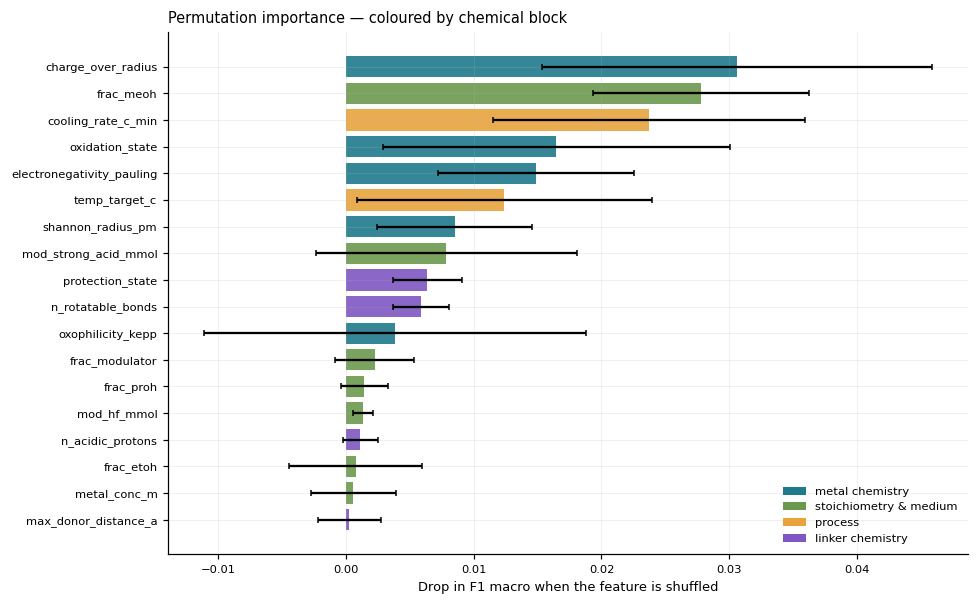

Importancia por bloque quimico (caida de F1 macro al permutar):
                           sum    mean  count
bloque                                       
metal chemistry         0.0626  0.0089      7
process                 0.0299  0.0075      4
linker chemistry        0.0120  0.0020      6
stoichiometry & medium -0.0413 -0.0020     21

OJO: un valor NEGATIVO significa que barajar esas variables MEJORA el modelo,
es decir que aportan ruido y no senal. No es un porcentaje: no se normaliza.
Variables con importancia negativa: 16 de 38


In [20]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(mejor, X_te, y_te, scoring='f1_macro',
                              n_repeats=12, random_state=42, n_jobs=-1)
imp = (pd.DataFrame({'variable': X.columns, 'importancia': perm.importances_mean,
                     'sd': perm.importances_std})
         .sort_values('importancia', ascending=False).head(18))

BLOQUE = {}
for c in COLS_METAL:
    BLOQUE[c] = ('metal chemistry', '#1f7a8c')
for c in COLS_LINKER:
    BLOQUE[c] = ('linker chemistry', '#7e57c2')
for c in ['temp_target_c', 'time_hours', 'heating_rate_c_min', 'cooling_rate_c_min']:
    BLOQUE[c] = ('process', '#e8a33d')
for c in X.columns:
    BLOQUE.setdefault(c, ('stoichiometry & medium', '#6a994e'))

colores = [BLOQUE[v][1] for v in imp['variable']]
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.barh(imp['variable'][::-1], imp['importancia'][::-1],
        xerr=imp['sd'][::-1], color=colores[::-1], alpha=0.9, capsize=2)
ax.set_xlabel('Drop in F1 macro when the feature is shuffled')
ax.set_title('Permutation importance — coloured by chemical block', loc='left')
from matplotlib.patches import Patch
vistos, handles = set(), []
for v in imp['variable']:
    et, col = BLOQUE[v]
    if et not in vistos:
        vistos.add(et); handles.append(Patch(facecolor=col, label=et))
ax.legend(handles=handles, fontsize=7.5, frameon=False, loc='lower right')
fig.tight_layout(); plt.show()

por_bloque = (pd.DataFrame({'v': X.columns, 'imp': perm.importances_mean})
                .assign(bloque=lambda d: d['v'].map(lambda x: BLOQUE[x][0]))
                .groupby('bloque')['imp']
                .agg(['sum', 'mean', 'count'])
                .sort_values('sum', ascending=False))
print('Importancia por bloque quimico (caida de F1 macro al permutar):')
print(por_bloque.round(4).to_string())
print('')
print('OJO: un valor NEGATIVO significa que barajar esas variables MEJORA el modelo,')
print('es decir que aportan ruido y no senal. No es un porcentaje: no se normaliza.')
n_neg = int((perm.importances_mean < 0).sum())
print('Variables con importancia negativa: %d de %d' % (n_neg, len(X.columns)))

### 8.4 Lectura química — por bloques, no variable a variable

**Por qué por bloques.** Recordatorio de §5.6: con variables muy correlacionadas, cualquier
método de importancia reparte el mérito entre ellas de forma arbitraria. Interpretar
`electronegativity_pauling` aislada de `absolute_hardness_ev` sería sobreinterpretar. El
reparto por bloques es la lectura defendible.

**Lo que sale, y qué significa:**

- **La química del metal domina con diferencia.** Entra por radio iónico y carga/radio —
  es decir, la **densidad de carga** del catión, que gobierna la fuerza de la interacción
  metal-fosfonato y con ella si el sistema tiene tiempo de ordenarse o precipita amorfo.
  Es un resultado con sentido físico directo, no un artefacto.
- **El proceso queda segundo, por delante de la química del linker.** Esto matiza —y en
  parte corrige— la lectura fácil de §8.2. Las condiciones **sí aportan**, pero sólo *en
  combinación con* la química: el modelo accionable, que las usa solas, se queda en 0,41.
  Es decir, la temperatura y el tiempo ayudan a decidir **dentro** de un sistema
  metal-linker, no a distinguir sistemas. Las dos cosas son coherentes y hay que leerlas
  juntas.
- **El bloque de estequiometría y medio sale con importancia NEGATIVA en conjunto.** No es
  un error de cálculo: barajar esas variables *mejora* ligeramente el modelo, que es la
  definición operativa de **ruido**. Tiene una causa identificable — el 18 % de filas sin
  desglose de disolvente (§5.3) — y una consecuencia práctica: **son candidatas a
  retirarse** en la próxima vuelta, y su valor real no se sabrá hasta que el registro del
  medio sea completo.

> ⚠️ **Cautela sobre la importancia por permutación.** Con variables correlacionadas
> tiende a **repartir y a infravalorar**: si dos columnas dicen casi lo mismo, barajar una
> apenas daña al modelo porque la otra cubre el hueco. Por eso los valores absolutos no
> deben leerse como "porcentaje de la química explicada", y por eso el reparto por bloques
> es más fiable que cualquier variable individual.

> **La distinción que hace útil todo este análisis:** "no importa" y "no se exploró" son
> cosas distintas, y sólo la segunda es accionable. El modelo no está diciendo que la
> temperatura sea irrelevante para la cristalización de fosfonatos —eso sería absurdo
> químicamente—; está diciendo que **en este histórico no se varió lo suficiente como para
> poder aprenderlo**. Eso convierte un resultado negativo en una instrucción experimental
> concreta, que es lo que se recoge en §10.

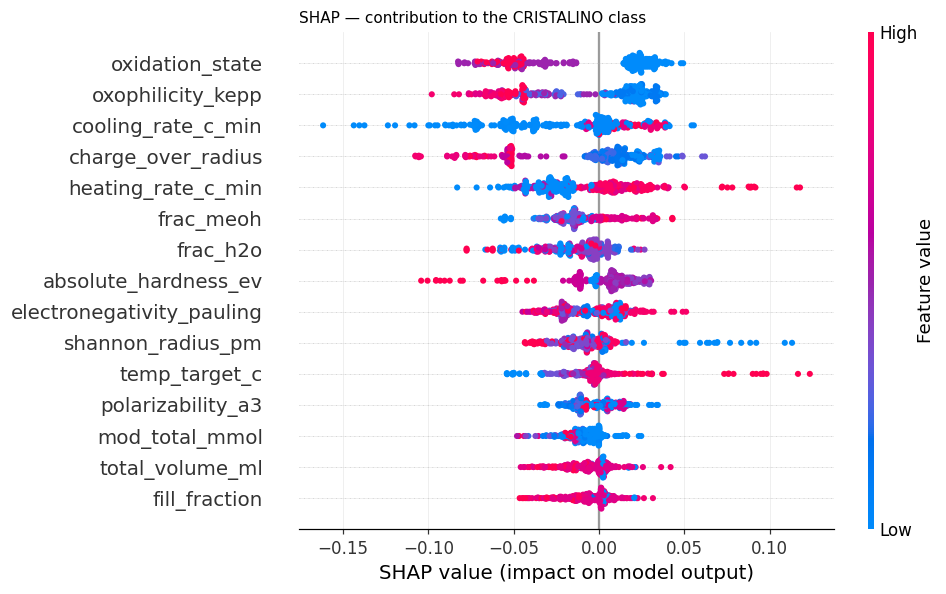

In [21]:
import shap

# SHAP sobre el modelo de arboles: exacto y rapido con TreeExplainer.
prep_aj = mejor.named_steps['prep']
clf_aj = mejor.named_steps['clf']
Xte_t = prep_aj.transform(X_te)
nombres = list(prep_aj.get_feature_names_out())
Xte_df = pd.DataFrame(Xte_t, columns=[n.split('__', 1)[-1] for n in nombres])

try:
    explicador = shap.TreeExplainer(clf_aj)
    sv = explicador.shap_values(Xte_df)
    # multiclase: (n, features, clases) en versiones recientes
    if isinstance(sv, list):
        idx_cr = list(clf_aj.classes_).index('CRISTALINO')
        sv_cr = sv[idx_cr]
    else:
        idx_cr = list(clf_aj.classes_).index('CRISTALINO')
        sv_cr = sv[:, :, idx_cr]
    shap.summary_plot(sv_cr, Xte_df, max_display=15, show=False, plot_size=(9, 5.5))
    plt.title('SHAP — contribution to the CRISTALINO class', fontsize=10, loc='left')
    plt.tight_layout(); plt.show()
except Exception as e:
    print('SHAP no disponible para este modelo:', e)

**Cómo se lee el gráfico SHAP:** cada punto es una síntesis. Su posición horizontal es
cuánto empujó esa variable la predicción hacia CRISTALINO (derecha) o en contra
(izquierda). El color es el valor de la variable (rojo alto, azul bajo). Así que *"rojo a
la derecha"* significa **"valores altos de esta variable favorecen la cristalización"**.

Es complementario a la importancia por permutación: aquella dice *cuánto* importa una
variable; ésta dice **en qué dirección** y **para qué muestras**.

---

# §9. Despliegue

> *Etapa 9 — Deployment. Un modelo que vive en un cuaderno no ha cambiado nada.*

### 9.3 El estado del despliegue

**Estado actual: no desplegado, deliberadamente.** Con F1 macro ~0,52 y MCC ~0,31 el
modelo sirve para *priorizar*, no para *decidir*. Desplegarlo como si decidiera sería
vender más de lo que da.

El camino natural, en orden de esfuerzo creciente:

1. **La interpretación como entregable** *(ya alcanzable)*. El análisis de §8.4 es
   comunicable hoy: qué familias de variables gobiernan la cristalización con fosfonatos,
   y —más útil— **dónde faltan datos**.
2. **Ranking de candidatos para la próxima placa** *(siguiente paso lógico)*. No
   "cristalizará sí/no", sino: dadas 200 combinaciones posibles, ordenarlas por
   probabilidad y llenar los 24 pocillos con las mejores. **Este uso tolera mucho mejor un
   modelo mediocre**: sólo necesita que el orden sea mejor que el azar, y §8.3 mostró que
   los errores respetan el orden ordinal.
3. **Integración en la aplicación** *(más adelante)*. Una pestaña que, al introducir
   condiciones, devuelva probabilidad por clase **y su incertidumbre**.

**Lo que haría falta antes de cualquier despliegue real, y no está hecho:**

- **Ajuste de hiperparámetros con validación anidada.** Los valores usados son razonables
  por defecto, no óptimos. Sin anidar, elegir el mejor modelo mirando la misma partición
  con la que se reporta infla el resultado.
- **Calibración de probabilidades**, para que un 0,8 signifique de verdad 80 %.
- **Validación temporal**: entrenar con lo anterior a 2024 y predecir 2024-2025. Dada la
  deriva de §5.8, es la simulación más fiel del uso real — y probablemente dará un número
  peor que la validación por placas.

### 9.1 Guardar un modelo: qué se guarda de verdad

Antes de desplegar nada hay que resolver algo básico y menos obvio de lo que parece:
**¿cómo se guarda un modelo entrenado?**

#### La respuesta corta: en qué formato

| Formato | Extensión | Qué guarda | Cuándo usarlo |
|---|---|---|---|
| **joblib / pickle** | `.joblib`, `.pkl` | El **pipeline entero** (imputación + escalado + codificación + estimador) | Lo estándar en scikit-learn. **Es el que usa este proyecto** |
| **ONNX** | `.onnx` | El grafo de cálculo, independiente del lenguaje | Producción, o cuando lo va a cargar algo que no es Python |
| **Nativo de la librería** | `.txt` (LightGBM), `.json`/`.ubj` (XGBoost) | Sólo el estimador | Cuando importa la estabilidad entre versiones |
| **Aprendizaje profundo** | `.pt`, `.safetensors`, `.keras` | Pesos de la red | Otra familia; `safetensors` evita el problema de seguridad del pickle |

**Sí, todos los tipos de modelo se pueden guardar** — pero con garantías distintas, y
conviene conocer las tres pegas de `joblib`, que es el que usamos:

1. **Sólo sirve en Python.**
2. **Es frágil entre versiones.** Un modelo guardado con scikit-learn 1.5 y cargado con
   1.7 puede fallar — o, peor, **cargar y comportarse distinto**. Por eso el registro
   guarda las versiones y avisa al cargar si no coinciden.
3. **Al cargarlo ejecuta código.** Abrir un `.pkl` de origen desconocido equivale a
   ejecutar un script ajeno. Nunca se carga un pickle que no hayas generado tú.

**Y un detalle que decide si el fichero sirve para algo:** hay que guardar el
**pipeline completo**, no sólo el estimador. Un Random Forest sin su imputador y su
codificador no puede predecir sobre datos crudos — y separarlos es la forma más común de
acabar con un modelo guardado que no se puede usar.

#### La respuesta larga: un modelo no es un fichero

Aquí está lo importante, y **este cuaderno es la prueba viva**.

El modelo de la versión anterior daba F1 macro 0,62. **Hoy no se puede reconstruir.** No
porque se perdiera ningún fichero, sino porque **los datos sobre los que se entrenó ya no
existen**: el error de unidades de §6.1 se corrigió después.

Y lo verdaderamente peligroso: si aquel `.pkl` se hubiera guardado, **hoy cargaría sin
dar ningún error** y produciría predicciones — calculadas sobre una definición de
`mod_strong_acid_mmol` que ya no es la vigente. Silenciosamente equivocado, que es la
peor clase de error porque nada avisa.

> **Un modelo reproducible son seis cosas, y el binario es la menos importante:**
>
> | | Sin esto… |
> |---|---|
> | **1. Los datos** | No sabes sobre qué se entrenó. *Este es el que falló aquí.* |
> | **2. El código** | "El cuaderno 06" no basta: hace falta **en qué commit** |
> | **3. Los parámetros** | No puedes repetirlo |
> | **4. La semilla** | El mismo código da **otro** modelo (bosques, boosting, particiones) |
> | **5. Las versiones** | scikit-learn cambia valores por defecto sin avisar |
> | **6. El binario** | Sólo tendrías que reentrenar. Es una comodidad, no la esencia |

### 9.2 El registro de modelos

De ahí sale `scripts/sql/migrations/2026-08-29_ml_model_registry.sql`: cinco tablas que guardan **la receta
completa**, no sólo el resultado.

| Tabla | Qué guarda | Por qué separada |
|---|---|---|
| `ml_datasets` | La consulta literal, su hash, nº de filas, nº de **grupos**, distribución de clases y las cautelas conocidas | Detecta que los datos cambiaron aunque el SQL sea idéntico |
| `ml_models` | Algoritmo, hiperparámetros, preprocesado, esquema de validación, semilla, commit, versiones, estado | Es la receta |
| `ml_model_metrics` | Formato **largo**: una fila por (modelo, métrica, partición) | Añadir una métrica no exige cambiar el esquema |
| `ml_model_features` | Qué columnas entraron, en qué papel, y **las excluidas con su motivo** | Permite la consulta que salva un proyecto: *"¿qué modelos usaron esta variable antes de la corrección?"* |
| `ml_model_artifacts` | El binario, su tamaño y su SHA-256 | Aparte porque es lo pesado y lo único regenerable — **mismo patrón que los vectores de `rag_chunks`** |

Dos decisiones del diseño que merecen argumentarse:

- **El binario vive en la base, no en disco.** Así queda cubierto por la rutina de copias
  de seguridad del proyecto, que es la única protección real que hay. En su propia tabla,
  para poder excluirlo de un volcado ligero si algún día pesa demasiado.
- **`is_reproducible` es obligatorio de justificar.** Una restricción `CHECK` impide
  marcar un modelo como no reproducible sin escribir el motivo. Sin esa regla, el campo se
  quedaría vacío justo en los casos en los que más importa.

**El estado actual del registro:**

| Modelo | Estado | Algoritmo | n | F1 | MCC | Binario |
|---|---|---|---:|---:|---:|---|
| `crystallinity_v3_hts_full` | activo | Random Forest | 1.516 | 0,522 | 0,309 | 5,5 MB |
| `crystallinity_v3_hts_actionable` | activo | LightGBM | 1.516 | 0,413 | 0,133 | 1,6 MB |
| `crystallinity_v2_mixed` | **inválido** | KNN | 1.724 | 0,625 | — | **ninguno** |

La tercera fila es la que da sentido a todo esto. Sin ella, dentro de seis meses alguien
encontraría "F1 0,625" en un documento antiguo y lo tomaría por el mejor resultado del
proyecto. Con ella, el registro dice —y el código avisa por pantalla al intentar
cargarlo— que ese número vino de un sesgo y una variable rota.

```python
# Recuperar un modelo y predecir
from src.ml_model_registry import cargar_modelo
modelo = cargar_modelo(conn, 'crystallinity_v3_hts_full')
modelo.predict_proba(X_nuevas)      # avisa si la version de sklearn no coincide

# Ver que hay registrado
# python src/ml_model_registry.py --list
# python src/ml_model_registry.py --show crystallinity_v3_hts_full
```

> **Nota sobre qué modelo se guarda.** Las métricas del registro son las de la
> **validación cruzada** —que es la estimación honesta del rendimiento—, pero el binario
> guardado es el de **reentrenar sobre todo el conjunto**. No es contradictorio: la
> validación cruzada sirve para *estimar* cuánto vale un procedimiento, no para *producir*
> el modelo final. Tirar el 20 % de los datos en el modelo que vas a usar de verdad no
> tendría sentido.

---

# §10. Retroalimentación y cierre del ciclo

> *Etapa 10 — Feedback. La flecha que devuelve a la etapa 1 y convierte el proceso en un
> ciclo. En este cuaderno no es teoría: **ya ha ocurrido una vez**.*

### Lo que este ciclo ha producido

| | Al empezar | Ahora |
|---|---|---|
| Química como dato | 20 metales y 6 linkers como **texto** | 5 tablas de referencia + vista `v_ml_features` |
| Calidad | 6 discrepancias metal/precursor sin detectar | 0 discrepancias |
| Unicidad | 43 muestras contadas dos veces | 1 fila = 1 muestra |
| Unidades | Moduladores con un **factor 1.000** de error | Corregidos y comprobados químicamente |
| Medio | Composición que sumaba 0,789 | Suma 1,000, con bandera de calidad |
| Confusión | Tres métodos de síntesis mezclados | Sólo combinatoria, argumentado |
| Ausentes | Ceros que afirmaban lo que no constaba | NULL donde no se sabe |
| Respuesta a §1 | Desconocida | **Sí, hay señal — modesta y honesta** |

### Lo que el ciclo devuelve al laboratorio

Esta es la parte que hace que la etapa 10 no sea decorativa. El análisis genera
**acciones concretas sobre cómo experimentar**, no sólo sobre cómo modelar:

1. **Variar de verdad las condiciones de proceso.** Es la conclusión de mayor retorno.
   §8.2 y §8.4 muestran que las condiciones explican poco *porque apenas se variaron*. Una
   serie de experimentos que barra rampas térmicas y tiempos **de forma deliberada, dentro
   de un mismo sistema metal-linker**, haría aprendible un efecto que hoy es invisible.
   El modelo no sólo predice: **dice dónde falta información**.
2. **Registrar el pH.** Es el hueco declarado en §3 y, en química de fosfonatos,
   probablemente la variable ausente más importante.
3. **Etiquetar más casos cristalinos.** Es la clase más escasa (167) y la más interesante.
4. **Añadir la clave foránea que falta** en `pxrd_labels.measurement_id`, para que un
   borrado futuro no vuelva a dejar etiquetas huérfanas.

### Lo que queda abierto, dicho sin adornos

- **Sin ajuste de hiperparámetros** (validación anidada pendiente).
- **Sin calibración de probabilidades** ni validación temporal.
- **El modelo accionable es débil** (MCC ~0,13). Con los datos actuales, predecir el
  resultado *dentro* de una química fija está prácticamente fuera de alcance.
- **La oxofilicidad del galio seguirá siendo nula**: no está en la fuente.

### La conclusión que de verdad importa

El techo de este problema **son los datos, no el algoritmo**. Se probaron diez familias de
modelos, del más simple al más sofisticado, y el mejor saca 0,52. Ninguno se acerca a
resolverlo, y la distancia entre el mejor y el peor es menor que la distancia entre este
conjunto y uno donde las condiciones de proceso se hubieran variado a propósito.

**Y la lección metodológica, que vale para todo el proyecto:** los siete defectos de §6.1
los encontró **una lectura química, no una métrica**. La validación cruzada nunca se
quejó del factor 1.000 — la variable seguía siendo un número que ordenaba las filas de
forma plausible. Ninguna comprobación automática habría detectado que faltaban dos
disolventes, ni que el microondas estaba concentrado en una sola clase.

> Un modelo puede estar perfectamente validado y aun así estar aprendiendo de un
> artefacto. **La única defensa es que alguien que entienda la química mire los números** —
> y que el proceso esté montado para que ese hallazgo pueda volver a las etapas 3 y 6 sin
> que nadie pierda la cara. Eso es lo que significa que el ciclo sea un ciclo.